<p style="text-align:center"><img src="../images/04_10_spatial_capstone.png" alt="Spatial Statistics Capstone" width="100%"></p>

# Capstone: Presidential Voting Patterns, 2020 vs 2024 -  Persistence and Shift

This is Part 10 (Capstone) of the spatial-statistics module. It is one political-geography study run end to end, from a SQL extract and CRS audit through to a decision log. A single 2024 map cannot tell a durable partisan geography apart from a change tied to the 2024 election. This notebook therefore compares **2020 and 2024 county presidential returns** and asks two questions of them:

1. **Persistence.** Which parts of the Republican/Democratic map, and of its socio-demographic correlates, were the same in both elections?
2. **Change.** Where did counties move between 2020 and 2024? Is that shift spatially clustered, and which county characteristics are associated with it?

All data come from the local **USA Health Data Atlas SQLite database** (`Data/00_shared/data_spatial_stat/usa_health_atlas_database/`): presidential returns (MEDSL 2020; tonmcg 2024), Census population estimates, County Health Rankings, the CDC/ATSDR Social Vulnerability Index, and the 2020 U.S. Religion Census. Geometry is `US_COUNTY.shp` (CONUS counties). The framing follows the course guideline *Votting Pattern.qmd*: socioeconomic and demographic variables, spatial autocorrelation, spatial regression, GWR, spatial clustering, and an explainable machine-learning cross-check.

## Overview

> Across contiguous-US counties, how much of the 2024 Republican vote geography was already present in 2020? Where did the two-party vote move between the two elections, does the move form spatial clusters, and which county characteristics (rurality, race/ethnicity, age, education, unemployment, poverty, population change, evangelical adherence) are associated with the **level** of support versus the **change** in support?

**Outcomes** (all in percentage points of the two-party vote, Republican ÷ (Republican + Democratic)):

| Variable | Definition | Role |
|---|---|---|
| `rep2p_2020` | GOP two-party share, 2020 | Persistent geography (baseline) |
| `rep2p_2024` | GOP two-party share, 2024 | Persistent geography (current) |
| `shift` | `rep2p_2024 − rep2p_2020` | Change associated with 2024 (positive = toward Republicans) |
| `rep_2024`, expected from 2020 share | Republican votes vs. the count expected if each county had kept its 2020 share | Count model for "was the shift real?" |

The two-party share is used instead of the all-candidate share so that changes in minor-party voting between 2020 and 2024 do not show up as partisan shift.

**Covariates**, all pre-2024 county conditions drawn from the Atlas database:

| Covariate | Atlas source (table `county_indicators`) | Year |
|---|---|---|
| `pct_rural` | Census PEP `PCT_RURAL` (2010 Census rural share) | constant |
| `pct_hispanic` | Census PEP `PCT_HISPANIC` | 2020 |
| `pct_nh_black` | Census PEP `PCT_NHBLACK` | 2020 |
| `pct_65plus` | Census PEP `PCT_65PLUS` | 2020 |
| `pct_some_college` | CHR `Some College` (adults 25–44 with post-secondary education) | CHR 2022 release |
| `pct_unemployed` | CHR `Unemployment` | CHR 2022 release (2020 BLS) |
| `poverty_pctile` | SVI 2022 `EPL_POV150` (percentile of residents < 150 % of poverty) | 2022 |
| `pop_change` | Census PEP `POP`, % change 2020 → 2023 | 2020–23 |
| `pct_evangelical` | Religion Census `dom_evan_rate` ÷ 10 (adherents per 100 residents) | 2020 |

These cover most of the guideline's priority list: poverty, unemployment, education, rural population, Hispanic and Black population, age 65+, population change, and religion. Median household income, foreign-born share, manufacturing employment, and union membership are not yet in the Atlas tables, so they are left for an extension.

| Step | What we do |
|------|------------|
| Data | SQL extract of 2020 + 2024 returns and covariates; FIPS join; data-quality rules; CRS audit |
| Persistence vs change | Side-by-side party maps, the shift map, a 2020-vs-2024 scatter |
| Weights | Queen contiguity with island linking; KNN sensitivity for all three outcomes |
| Autocorrelation | Global Moran's I for 2020, 2024, and the shift |
| Clusters | LISA in each year and the 2020→2024 cluster transition matrix; Gi* and LISA on the shift; SKATER regions on level + shift |
| Explanation | The same OLS for 2020, 2024, and the shift; LM tests; SLM and SEM |
| Heterogeneity | GWR and MGWR on the shift; local Hispanic-share slopes in 2020 vs 2024 |
| Counts | SMR → empirical Bayes → BYM of 2024 GOP votes against a "kept-2020-share" expectation |
| Machine learning | XGBoost with state-grouped CV and TreeSHAP attributions for the shift |
| Reporting | Decision log and a one-page summary figure |

**Caveats that apply to every result below.**
- *Ecological fallacy:* county characteristics and county results show **geographic associations**, not how individuals voted.
- *Source change:* the Atlas documents 2004–2020 returns from MEDSL and 2024 returns from a compiled, **provisional (non-certified)** tonmcg county feed. Part of any county-level "shift" can be a difference between sources.
- *Coverage:* Connecticut reports 2024 results by planning region, which does not match its 2020 county FIPS, so Connecticut is dropped. D.C., Alaska, and Hawaii are outside the CONUS county layer.

Every number in the prose is computed in this notebook. The random seed, permutation count, and α are fixed in Setup and repeated in the decision log.

## API overview

```
- sqlite3 (standard library) → USA Health Data Atlas database
- SpatialData
- W, Queen, KNN
- Moran, moran_scatter
- getis_ord_gi, local_moran_clusters, skater, jaccard, agreement_matrix
- OLS, SpatialLag, SpatialError, compare_models
- GWR, MGWR
- smr, eb_gamma_poisson, BYM
- xgboost.XGBRegressor (TreeSHAP via pred_contribs), sklearn GroupKFold
```

## Setup

Locate the repository root, import the spatial-statistics helpers, and point `DB` at the Atlas SQLite database.

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import sys
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from pyproj import Transformer
from scipy.spatial import cKDTree
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat"
DB = DATA / "usa_health_atlas_database" / "usa_health_atlas.sqlite"

import geolattice.spatial_statistics
from geolattice.viz import apply_map_style

from geolattice.spatial_statistics.core import SpatialData
from geolattice.spatial_statistics.weights import W, Queen, KNN
from geolattice.spatial_statistics.esda import Moran
from geolattice.spatial_statistics.viz import moran_scatter
from geolattice.spatial_statistics.cluster import (
    getis_ord_gi, local_moran_clusters, skater, jaccard, agreement_matrix,
)
from geolattice.spatial_statistics.regression import OLS, SpatialLag, SpatialError, compare_models
from geolattice.spatial_statistics.gwmodel.linear import GWR, MGWR
from geolattice.spatial_statistics.bayes import smr, eb_gamma_poisson, BYM

SEED = 7
PERM = 999
ALPHA = 0.05
YEARS = (2020, 2024)

# Outcomes: two persistent-geography levels and the 2020→2024 change.
OUTCOMES = {
    "rep2p_2020": "GOP two-party share 2020 (%)",
    "rep2p_2024": "GOP two-party share 2024 (%)",
    "shift": "Shift 2020→2024 (pp, + = toward GOP)",
}

# Covariates: (Atlas dataset, Atlas variable, Atlas year) for each analysis column.
COVAR_SPEC = {
    "pct_rural":        ("census_demography", "PCT_RURAL", 2020),
    "pct_hispanic":     ("census_demography", "PCT_HISPANIC", 2020),
    "pct_nh_black":     ("census_demography", "PCT_NHBLACK", 2020),
    "pct_65plus":       ("census_demography", "PCT_65PLUS", 2020),
    "pct_some_college": ("county_health_rankings", "Some College", 2022),
    "pct_unemployed":   ("county_health_rankings", "Unemployment", 2022),
    "poverty_pctile":   ("social_vulnerability_index", "EPL_POV150", 2022),
    "pop_change":       ("census_demography", "POP", (2020, 2023)),
    "pct_evangelical":  ("religion_census", "dom_evan_rate", 2020),
}
COVARS = list(COVAR_SPEC)
COVAR_LABELS = {
    "pct_rural": "% rural",
    "pct_hispanic": "% Hispanic",
    "pct_nh_black": "% non-Hispanic Black",
    "pct_65plus": "% age 65+",
    "pct_some_college": "% some college (25–44)",
    "pct_unemployed": "% unemployed",
    "poverty_pctile": "Poverty <150% FPL (percentile)",
    "pop_change": "% population change 2020–23",
    "pct_evangelical": "% evangelical Protestant",
}

apply_map_style()
COLORS = {
    "blue": "#2b6cb0", "red": "#c0392b", "green": "#2f855a",
    "orange": "#dd6b20", "grey": "#718096", "purple": "#6b46c1", "teal": "#2c7a7b",
}
print(f"geolattice.spatial_statistics : version {geolattice.spatial_statistics.__version__}")
print(f"database : {DB.relative_to(ROOT)}  ({DB.stat().st_size / 1e6:.0f} MB)")
print(f"seed {SEED}  |  permutations {PERM}  |  alpha {ALPHA}  |  years {YEARS}")

geolattice.spatial_statistics : version 0.3.49
database : Data/00_shared/data_spatial_stat/usa_health_atlas_database/usa_health_atlas.sqlite  (162 MB)
seed 7  |  permutations 999  |  alpha 0.05  |  years (2020, 2024)


## Data: the USA Health Data Atlas database

The Atlas publishes its county data as JavaScript bundles. `data_processing.py` (in this folder) creates the SQLite schema and dataset catalog and then calls `build_database.py`, which downloads the bundles and parses each one into normalized tables:

| Table | Content used here |
|---|---|
| `presidential_election_results` | One row per county × year (2004–2024): votes, shares, margin, **source** |
| `county_indicators` | Long table `(dataset_id, fips, year, variable, value, unit)` for Census PEP, CHR, SVI, Religion Census |
| `dataset_catalog`, `data_load_log`, `source_records` | Provenance: dataset descriptions, import status, each bundle's metadata |

If the database is empty, build it once (internet required, about 1 minute):

```bash
python Tutorials/notebooks/04_spatial_statistics/04_10_capstone/data_processing.py
```

The cell below stops early if the tables are empty, then shows which sources supplied each election year.

In [2]:
con = sqlite3.connect(DB)

# Row count of every table: a populated database has election and indicator rows.
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", con)["name"]
table_rows = pd.Series({t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in tables}, name="rows")
display(table_rows.to_frame())
if table_rows.get("presidential_election_results", 0) == 0:
    raise RuntimeError(
        "The Atlas database has no election rows yet. Run data_processing.py "
        "(or build_database.py) in this folder first."
    )

# Which source supplied each election year, and how many counties it covers.
display(pd.read_sql(
    """SELECT year, source, COUNT(*) AS counties,
              SUM(total_votes) AS total_votes,
              ROUND(100.0 * SUM(rep_votes) / SUM(rep_votes + dem_votes), 2) AS gop_two_party_pct
       FROM presidential_election_results
       GROUP BY year, source ORDER BY year""",
    con,
))
display(pd.read_sql("SELECT dataset_name, rows_loaded, status, loaded_at FROM data_load_log "
                    "WHERE status = 'success' ORDER BY load_id DESC LIMIT 5", con))

,rows
counties,3283
county_indicators,1624712
data_load_log,5
dataset_catalog,12
presidential_election_results,18929
source_records,5
sqlite_stat1,8
sqlite_stat4,121


,year,source,counties,total_votes,gop_two_party_pct
0,2004,MIT Election Data & Science Lab (MEDSL),3154,122320549,51.26
1,2008,MIT Election Data & Science Lab (MEDSL),3154,131187337,46.32
2,2012,MIT Election Data & Science Lab (MEDSL),3154,129044611,47.99
3,2016,MIT Election Data & Science Lab (MEDSL),3154,136490833,48.89
4,2020,MIT Election Data & Science Lab (MEDSL),3153,158131980,47.83
5,2024,"tonmcg county feed (provisional, non-certified)",3160,154863739,50.75


,dataset_name,rows_loaded,status,loaded_at
0,county_health_rankings,569997,success,2026-11-09 22:26:46
1,religion_census,116852,success,2026-11-09 22:26:43
2,social_vulnerability_index,66024,success,2026-11-09 22:26:42
3,census_demography,871839,success,2026-11-09 22:26:42
4,presidential_election,18929,success,2026-11-09 22:26:40


### SQL extract: one row per county with both elections

The election table is long (county × year). We pivot it to wide in SQL so that each county carries its 2020 and 2024 counts side by side. Covariates come from `county_indicators` in a second query. Each `(dataset, variable, year)` triple in `COVAR_SPEC` becomes one column, with a few unit conversions:

- CHR and SVI proportions (0–1) become percentages.
- The Religion Census rate per 1,000 residents becomes per 100, capped at 100. Adherent counts above a county's population are a known artifact of the Religion Census in small counties.
- Population change is computed from the 2020 and 2023 PEP totals.

A county that the Religion Census covered (it has a total-adherents rate) but that reports no evangelical bodies gets **0** evangelical adherents, not a missing value. These are mostly small Plains and Mountain counties dominated by Catholic or LDS congregations. If a county is absent from the 2020 census entirely, its 2010 value is used.

In [3]:
ELECTION_SQL = """
SELECT fips,
       MAX(county_name)                                  AS county_name,
       MAX(state_name)                                   AS state_abbr,
       MAX(CASE WHEN year = 2020 THEN rep_votes   END)   AS rep_2020,
       MAX(CASE WHEN year = 2020 THEN dem_votes   END)   AS dem_2020,
       MAX(CASE WHEN year = 2020 THEN total_votes END)   AS tot_2020,
       MAX(CASE WHEN year = 2024 THEN rep_votes   END)   AS rep_2024,
       MAX(CASE WHEN year = 2024 THEN dem_votes   END)   AS dem_2024,
       MAX(CASE WHEN year = 2024 THEN total_votes END)   AS tot_2024
FROM presidential_election_results
WHERE year IN (2020, 2024)
GROUP BY fips
"""
votes = pd.read_sql(ELECTION_SQL, con)

# One query for every (dataset, variable, year) the covariates need.
wanted = set()
for dataset, variable, year in COVAR_SPEC.values():
    for yr in (year if isinstance(year, tuple) else (year,)):
        wanted.add((dataset, variable, yr))
for yr in (2010, 2020):                                         # evangelical gap rules (see markdown)
    wanted.add(("religion_census", "dom_evan_rate", yr))
    wanted.add(("religion_census", "tot_rate", yr))
clauses = " OR ".join(["(d.dataset_name = ? AND i.variable = ? AND i.year = ?)"] * len(wanted))
INDICATOR_SQL = f"""
SELECT i.fips, d.dataset_name, i.variable, i.year, i.value
FROM county_indicators AS i
JOIN dataset_catalog  AS d USING (dataset_id)
WHERE {clauses}
"""
params = [p for triple in sorted(wanted) for p in triple]
long = pd.read_sql(INDICATOR_SQL, con, params=params)
wide = long.pivot_table(index="fips", columns=["dataset_name", "variable", "year"], values="value")
con.close()

covs = pd.DataFrame(index=wide.index)
for name, (dataset, variable, year) in COVAR_SPEC.items():
    if name == "pop_change":
        y0, y1 = year
        covs[name] = 100 * (wide[(dataset, variable, y1)] / wide[(dataset, variable, y0)] - 1)
    elif name == "pct_evangelical":
        # A county the census covered (tot_rate present) but with no evangelical bodies has 0 adherents.
        evan = {yr: wide[(dataset, variable, yr)].where(
                    wide[(dataset, variable, yr)].notna() | wide[(dataset, "tot_rate", yr)].isna(), 0.0)
                for yr in (2010, 2020)}
        covs[name] = (evan[2020].fillna(evan[2010]) / 10).clip(upper=100)
    elif dataset in ("county_health_rankings", "social_vulnerability_index"):
        covs[name] = 100 * wide[(dataset, variable, year)]
    else:
        covs[name] = wide[(dataset, variable, year)]
covs = covs.reset_index()

# Outcomes: GOP two-party shares and the shift between them.
votes["rep2p_2020"] = 100 * votes["rep_2020"] / (votes["rep_2020"] + votes["dem_2020"])
votes["rep2p_2024"] = 100 * votes["rep_2024"] / (votes["rep_2024"] + votes["dem_2024"])
votes["shift"] = votes["rep2p_2024"] - votes["rep2p_2020"]
votes["turnout_ratio"] = votes["tot_2024"] / votes["tot_2020"]

table = votes.merge(covs, on="fips", how="left")
display(Markdown(
    f"SQL returned **{len(votes)}** counties with at least one of the two elections and "
    f"**{len(long):,}** indicator values for **{len(covs)}** counties."
))
display(table[["fips", "county_name", "state_abbr", "rep2p_2020", "rep2p_2024", "shift", *COVARS]].head().round(2))

SQL returned **3170** counties with at least one of the two elections and **40,804** indicator values for **3234** counties.

,fips,county_name,state_abbr,rep2p_2020,rep2p_2024,shift,pct_rural,pct_hispanic,pct_nh_black,pct_65plus,pct_some_college,pct_unemployed,poverty_pctile,pop_change,pct_evangelical
0,01001,Autauga County,AL,72.56,73.36,0.80,42.00,3.63,20.23,15.76,60.72,4.88,36.21,2.42,38.25
1,01003,Baldwin County,AL,77.27,79.35,2.08,42.28,5.46,8.49,21.03,65.53,5.61,26.38,8.70,28.09
2,01005,Barbour County,AL,53.86,57.41,3.55,67.79,5.98,47.07,19.79,38.36,7.05,93.60,-1.54,36.98
3,01007,Bibb County,AL,79.12,82.38,3.27,68.35,3.26,20.65,17.14,37.77,6.63,75.15,-1.44,43.87
4,01009,Blount County,AL,90.35,90.78,0.43,89.95,9.76,1.53,18.52,56.27,4.09,49.00,1.20,47.25


### Join to county polygons, data-quality rules, and CRS audit

1. Zero-pad shapefile FIPS to five characters and inner-join to the SQL table.
2. **Coverage rule.** A county needs both elections and every covariate. This removes Connecticut, whose 2024 planning regions don't match its 2020 counties.
3. **Comparability rule.** Flag counties whose 2024 ballot total is under ⅔ or over 1.5× the 2020 total. A jump that large usually means the two sources drew the county's boundary differently. Jackson County, MO is the textbook case: MEDSL reports Kansas City separately in 2020, while the 2024 feed folds it into the county.
4. Audit the CRS and geometry, and keep the layer in metres (EPSG:5070).

Analysis coordinates are **polygon centroids of the projected geometry**.

In [4]:
def crs_audit(gdf, name="layer"):
    """Return a DataFrame of data-quality checks for a GeoDataFrame."""
    rows = []
    add = lambda check, status, detail: rows.append({"check": check, "status": status, "detail": detail})
    crs = gdf.crs
    if crs is None:
        add("CRS declared", "FAIL", "no CRS: cannot reproject and units are unknown")
    else:
        add("CRS declared", "ok", crs.name)
        unit = crs.axis_info[0].unit_name
        add(
            "metric projected CRS",
            "ok" if crs.is_projected and unit == "metre" else "warn",
            f"{'geographic' if crs.is_geographic else 'projected'}, unit = {unit}",
        )
        if crs.area_of_use is not None:
            pts = gdf.geometry.representative_point()
            if crs.is_geographic:
                lon, lat = pts.x.to_numpy(), pts.y.to_numpy()
            else:
                lon, lat = Transformer.from_crs(crs, 4326, always_xy=True).transform(
                    pts.x.to_numpy(), pts.y.to_numpy()
                )
            w, s, e, n = crs.area_of_use.bounds
            in_lon = (lon >= w) & (lon <= e) if w <= e else (lon >= w) | (lon <= e)
            frac = float(np.mean(in_lon & (lat >= s) & (lat <= n)))
            add("inside the CRS's area of use", "ok" if frac > 0.99 else "FAIL",
                f"{100 * frac:.0f}% of features")
    bad = int((~gdf.geometry.is_valid).sum())
    empty = int(gdf.geometry.is_empty.sum())
    miss = int(gdf.geometry.isna().sum())
    add("valid, non-empty geometries", "ok" if bad + empty + miss == 0 else "warn",
        f"{bad} invalid, {empty} empty, {miss} missing")
    types = gdf.geom_type.value_counts().to_dict()
    add("geometry types", "ok" if len(types) == 1 else "note", str(types))
    add("unique index", "ok" if gdf.index.is_unique else "warn",
        f"{int(gdf.index.duplicated().sum())} duplicated index labels")
    return pd.DataFrame(rows).set_index("check")


shp = gpd.read_file(DATA / "US_COUNTY.shp")
shp["fips"] = shp["FIPS"].astype(int).astype(str).str.zfill(5)
merged = shp[["fips", "STATE", "COUNTY", "geometry"]].merge(table, on="fips", how="inner")
n_shp, n_join = len(shp), len(merged)

# Rule 2: both elections and all covariates present.
need = ["rep2p_2020", "rep2p_2024", *COVARS]
missing = merged[need].isna().any(axis=1)
# Rule 3: ballot totals comparable between the two sources.
not_comparable = ~missing & ~merged["turnout_ratio"].between(2 / 3, 1.5)

dropped = pd.concat([
    merged.loc[missing, ["fips", "COUNTY", "STATE"]].assign(reason="missing election year or covariate"),
    merged.loc[not_comparable, ["fips", "COUNTY", "STATE", "turnout_ratio", "shift"]]
          .assign(reason="2024/2020 ballot ratio outside [0.67, 1.5]"),
])
merged = merged.loc[~missing & ~not_comparable].copy()
merged = merged.set_crs(5070, allow_override=True)        # NAD83 Conus Albers (metres)

audit = crs_audit(merged)
audit.loc["FIPS join"] = ("ok", f"shp={n_shp}, joined={n_join}, kept={len(merged)}, dropped={len(dropped)}")

study = SpatialData(merged, y="shift", X=COVARS + ["rep2p_2020", "rep2p_2024"])
counties = study.gdf.reset_index(drop=True)
centroids = counties.geometry.centroid
coords = np.column_stack([centroids.x.to_numpy(), centroids.y.to_numpy()])

display(audit)
display(dropped.round(3))
display(Markdown(
    f"**{len(counties)}** counties remain (geometry **{study.geometry_type}**, CRS **EPSG:{counties.crs.to_epsg()}**). "
    f"Dropped: **{int(missing.sum())}** for coverage "
    f"({int((dropped['STATE'] == 'Connecticut').sum())} Connecticut counties, whose 2024 results are by planning region) and "
    f"**{int(not_comparable.sum())}** for incomparable ballot totals."
))

,status,detail
check,,
CRS declared,ok,NAD83 / Conus Albers
metric projected CRS,ok,"projected, unit = metre"
inside the CRS's area of use,ok,100% of features
"valid, non-empty geometries",ok,"0 invalid, 0 empty, 0 missing"
geometry types,note,"{'Polygon': 3023, 'MultiPolygon': 74}"
unique index,ok,0 duplicated index labels
FIPS join,ok,"shp=3108, joined=3107, kept=3097, dropped=10"


,fips,COUNTY,STATE,reason,turnout_ratio,shift
983,09001,Fairfield County,Connecticut,missing election year or covariate,NaN,NaN
1234,11001,District of Columbia,District of Columbia,missing election year or covariate,NaN,NaN
1376,09015,Windham County,Connecticut,missing election year or covariate,NaN,NaN
1452,09005,Litchfield County,Connecticut,missing election year or covariate,NaN,NaN
1610,09007,Middlesex County,Connecticut,missing election year or covariate,NaN,NaN
1978,09003,Hartford County,Connecticut,missing election year or covariate,NaN,NaN
1998,09013,Tolland County,Connecticut,missing election year or covariate,NaN,NaN
2280,09011,New London County,Connecticut,missing election year or covariate,NaN,NaN
2909,09009,New Haven County,Connecticut,missing election year or covariate,NaN,NaN
1459,29095,Jackson County,Missouri,"2024/2020 ballot ratio outside [0.67, 1.5]",1.617,-11.892


**3097** counties remain (geometry **Mixed**, CRS **EPSG:5070**). Dropped: **9** for coverage (8 Connecticut counties, whose 2024 results are by planning region) and **1** for incomparable ballot totals.

## Persistence vs Change at a Glance

First the Republican two-party share in **2020**, the same share in **2024**, and their **difference** (`shift` = 2024 − 2020), all on one row. The Democratic share is just the complement of the Republican share, so it is not plotted separately.

The 2020 and 2024 maps should look almost the same — that is the persistence finding, not a plotting bug. County shares correlate at about **r = 0.995**, so a 20–80 % colour scale cannot show the 1–3 point moves. The third panel uses a tight diverging scale so those small moves become visible.

rep2p_2020 vs rep2p_2024:  identical counties = 0 / 3097,  mean |diff| = 1.87 pp,  max |diff| = 14.07 pp,  r = 0.9949


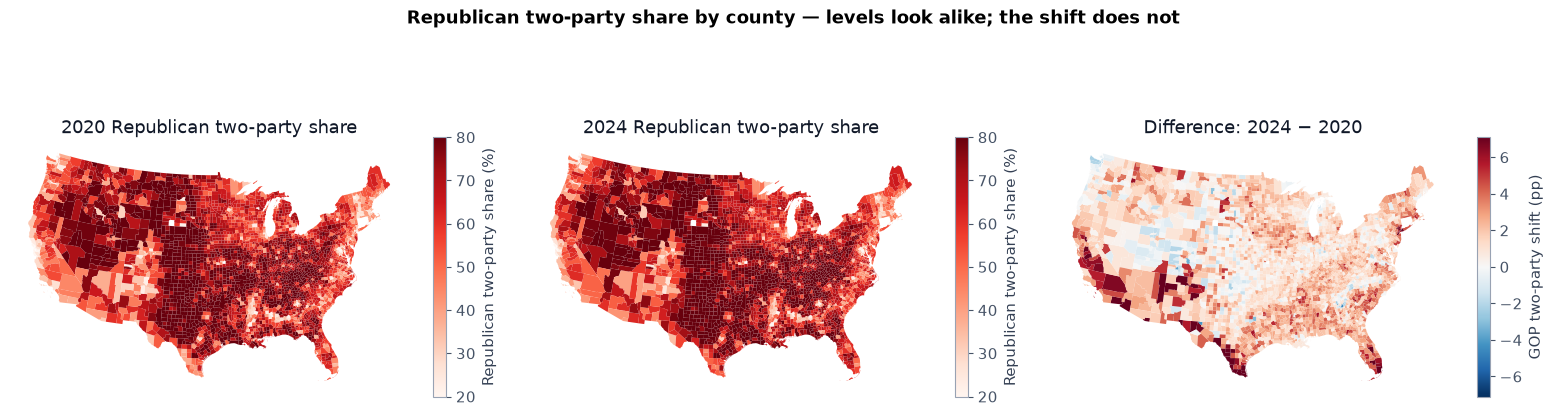

In [5]:
# Democratic two-party share is the complement of the GOP two-party share.
counties["dem2p_2020"] = 100 - counties["rep2p_2020"]
counties["dem2p_2024"] = 100 - counties["rep2p_2024"]

# Sanity check: prove the year columns are not identical.
y20 = counties["rep2p_2020"].to_numpy(dtype=float)
y24 = counties["rep2p_2024"].to_numpy(dtype=float)
diff = y24 - y20
print(
    f"rep2p_2020 vs rep2p_2024:  "
    f"identical counties = {(diff == 0).sum()} / {len(diff)},  "
    f"mean |diff| = {np.mean(np.abs(diff)):.2f} pp,  "
    f"max |diff| = {np.max(np.abs(diff)):.2f} pp,  "
    f"r = {np.corrcoef(y20, y24)[0, 1]:.4f}"
)

# Three panels: 2020 level, 2024 level, and the difference that the level maps hide.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Left / middle: same 20–80 % scale so the years are comparable.
for ax, col, title in [
    (axes[0], "rep2p_2020", "2020 Republican two-party share"),
    (axes[1], "rep2p_2024", "2024 Republican two-party share"),
]:
    counties.plot(
        column=col,
        cmap="Reds",
        vmin=20, vmax=80,
        legend=True,
        ax=ax,
        edgecolor="none",
        legend_kwds={"label": "Republican two-party share (%)", "shrink": 0.6},
    )
    ax.set_axis_off()
    ax.set_title(title)

# Right: same quantity as counties["shift"], on a tight diverging scale.
lim = float(np.nanpercentile(np.abs(diff), 99))
counties.plot(
    column="shift",
    cmap="RdBu_r",                                          # red = toward GOP, blue = toward Democrats
    norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),      # white = no change
    legend=True,
    ax=axes[2],
    edgecolor="none",
    legend_kwds={"label": "GOP two-party shift (pp)", "shrink": 0.6},
)
axes[2].set_axis_off()
axes[2].set_title("Difference: 2024 − 2020")

fig.suptitle(
    "Republican two-party share by county — levels look alike; the shift does not",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
# ALT: Three CONUS choropleths of Republican two-party share in 2020, the same share in 2024, and their difference; the first two maps look nearly identical while the third shows mostly light-to-dark red with stronger rightward shifts in South Texas, Florida, and large metros.
plt.show()

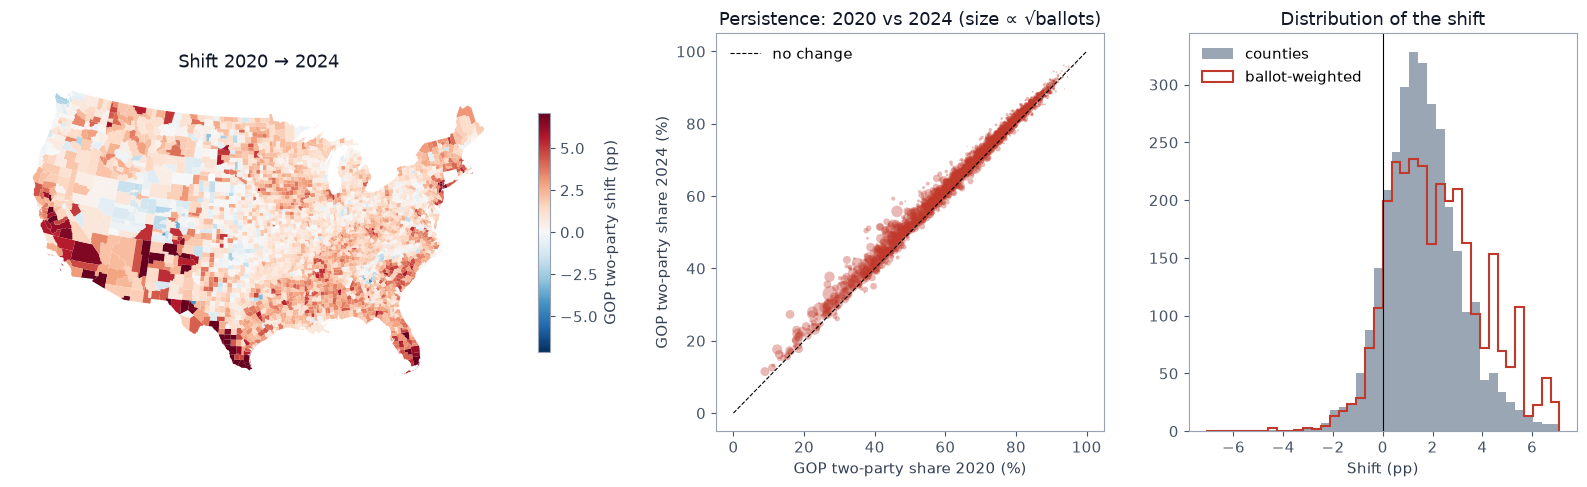

,COUNTY,STATE,rep2p_2020,rep2p_2024,shift
2782,Maverick County,Texas,45.2,59.3,14.1
1231,Imperial County,California,37.5,50.4,12.9
2091,Webb County,Texas,38.2,51.1,12.9
281,Bronx County,New York,16.0,27.3,11.3
1941,Starr County,Texas,47.5,58.0,10.5


County shares are almost perfectly persistent: **r = 0.995** between 2020 and 2024. Yet **88%** of counties moved toward the GOP. The median county shift was **+1.53 pp**, and the ballot-weighted mean was **+2.39 pp**. The weighted mean is larger than the median: big, more Democratic counties moved further right than small rural counties, which were already near their ceiling.

In [6]:
y20 = counties["rep2p_2020"].to_numpy(dtype=float)
y24 = counties["rep2p_2024"].to_numpy(dtype=float)
dy = counties["shift"].to_numpy(dtype=float)
ballots = (counties["rep_2024"] + counties["dem_2024"]).to_numpy(dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.6, 1, 1]})

# Left: shift map, diverging around zero (red = moved toward GOP, blue = toward Democrats).
lim = float(np.nanpercentile(np.abs(dy), 99))            # symmetric limits that ignore the extreme 1 %
counties.plot(
    column="shift",
    cmap="RdBu_r",                                        # red positive, blue negative
    norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),    # white exactly at "no change"
    legend=True, ax=axes[0], edgecolor="none",
    legend_kwds={"label": "GOP two-party shift (pp)", "shrink": 0.6},
)
axes[0].set_axis_off()
axes[0].set_title("Shift 2020 → 2024")

# Middle: 2020 vs 2024 share; points on the 45° line kept their 2020 share.
axes[1].scatter(y20, y24, s=np.sqrt(ballots) / 15, c=COLORS["red"], alpha=0.35, linewidths=0)
axes[1].plot([0, 100], [0, 100], color="black", lw=0.8, ls="--", label="no change")
axes[1].set_xlabel("GOP two-party share 2020 (%)")
axes[1].set_ylabel("GOP two-party share 2024 (%)")
axes[1].set_title("Persistence: 2020 vs 2024 (size ∝ √ballots)")
axes[1].legend(frameon=False, loc="upper left")

# Right: distribution of the shift, unweighted and ballot-weighted.
bins = np.linspace(-lim, lim, 41)
axes[2].hist(dy, bins=bins, color=COLORS["grey"], alpha=0.7, label="counties")
axes[2].hist(dy, bins=bins, weights=ballots / ballots.mean(), histtype="step", color=COLORS["red"], lw=1.5,
             label="ballot-weighted")
axes[2].axvline(0, color="black", lw=0.8)
axes[2].set_xlabel("Shift (pp)")
axes[2].set_title("Distribution of the shift")
axes[2].legend(frameon=False)
plt.tight_layout()
# ALT: Left, CONUS map of the 2020-to-2024 GOP two-party shift, mostly light red with strong red in South Texas, South Florida and large metros; middle, 2020 vs 2024 share hugging the 45-degree line; right, histogram of shifts centred just above zero.
plt.show()

r_persist = float(np.corrcoef(y20, y24)[0, 1])
weighted_shift = float(np.average(dy, weights=ballots))
top = counties.nlargest(5, "shift")[["COUNTY", "STATE", "rep2p_2020", "rep2p_2024", "shift"]]
display(top.round(1))
display(Markdown(
    f"County shares are almost perfectly persistent: **r = {r_persist:.3f}** between 2020 and 2024. "
    f"Yet **{(dy > 0).mean() * 100:.0f}%** of counties moved toward the GOP. "
    f"The median county shift was **{np.median(dy):+.2f} pp**, and the ballot-weighted mean was "
    f"**{weighted_shift:+.2f} pp**. The weighted mean is larger than the median: big, more Democratic "
    f"counties moved further right than small rural counties, which were already near their ceiling."
))

### Covariate maps and collinearity

The nine baseline covariates, then variance-inflation factors (VIF). A VIF above about 5 would warn that two covariates carry nearly the same information, which inflates the uncertainty of their coefficients in OLS and GWR.

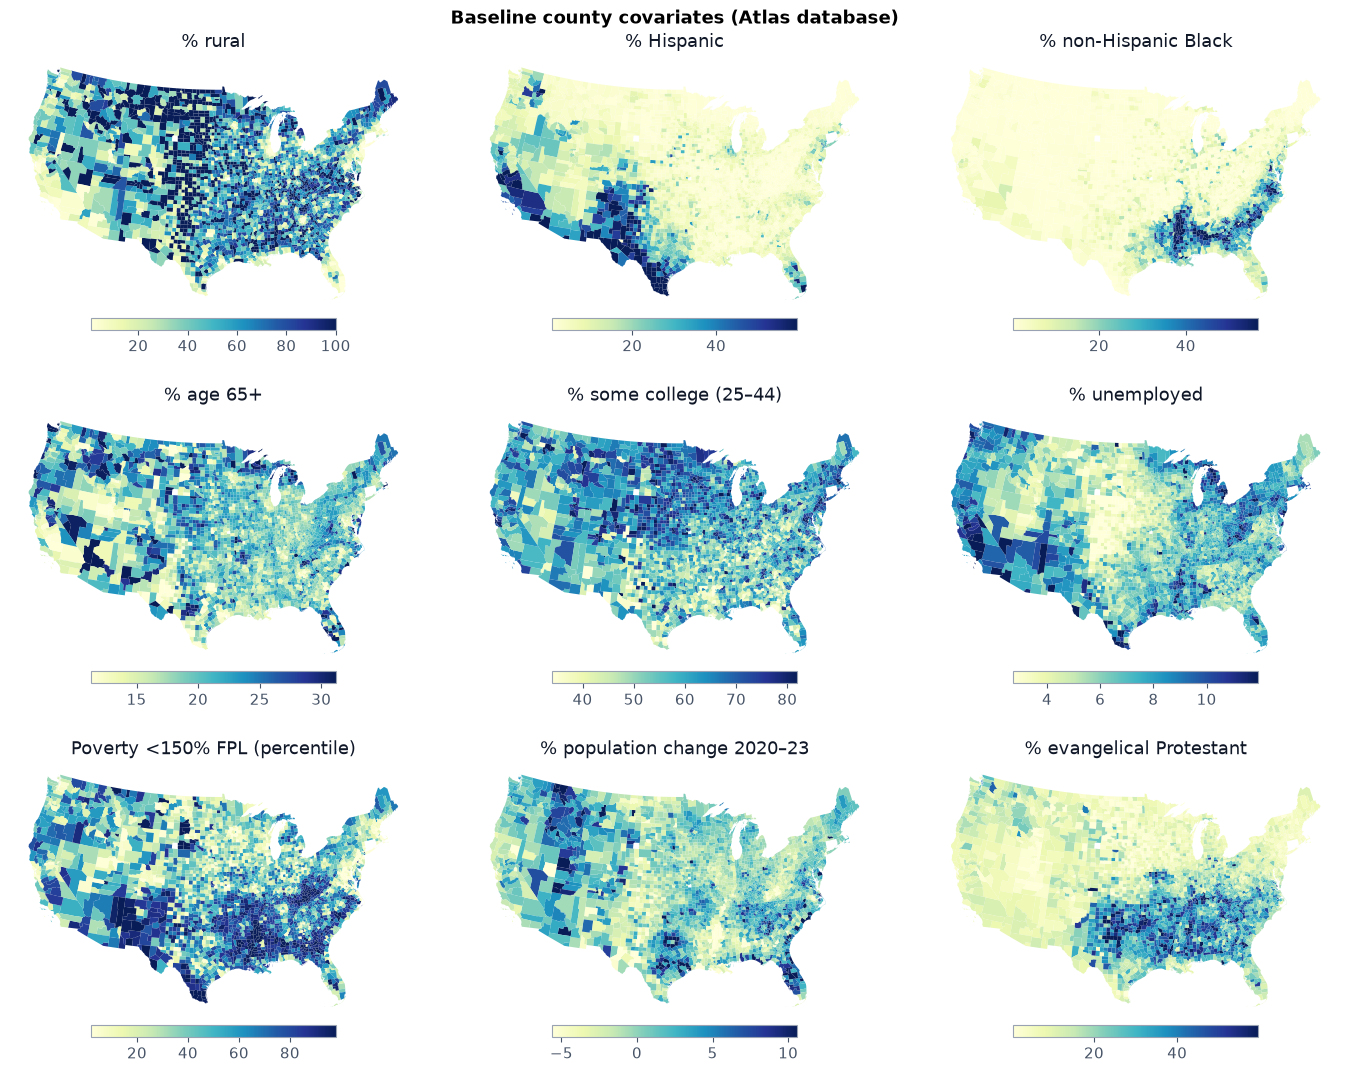

covariate,% rural,% Hispanic,% non-Hispanic Black,% age 65+,% some college (25–44),% unemployed,Poverty <150% FPL (percentile),% population change 2020–23,% evangelical Protestant
VIF,1.87,1.32,1.39,1.42,1.9,1.31,1.94,1.09,1.37


In [7]:
# 3 × 3 grid: one panel per covariate.
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, col in zip(axes.ravel(), COVARS):
    vals = counties[col]
    counties.plot(
        column=col,                                  # covariate to map
        cmap="YlGnBu",                               # sequential palette (low → high)
        vmin=vals.quantile(0.02),                    # clip 2 % tails so outliers don't wash out the map
        vmax=vals.quantile(0.98),
        legend=True, ax=ax, edgecolor="none",
        legend_kwds={"shrink": 0.55, "orientation": "horizontal", "pad": 0.02},
    )
    ax.set_axis_off()
    ax.set_title(COVAR_LABELS[col])
plt.suptitle("Baseline county covariates (Atlas database)", fontsize=13, fontweight="bold")
plt.tight_layout()
# ALT: Nine CONUS choropleths of rural share, Hispanic share, non-Hispanic Black share, age 65+, some college, unemployment, poverty percentile, population change 2020-23, and evangelical Protestant adherence.
plt.show()

# Standardise covariates once; every model below uses these z-scores so slopes are comparable.
X_raw = counties[COVARS].to_numpy(dtype=float)
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)


def vif(Z):
    """Variance-inflation factor of each column of Z (regress it on the others)."""
    out = []
    for j in range(Z.shape[1]):
        others = np.column_stack([np.ones(len(Z)), np.delete(Z, j, axis=1)])
        beta, *_ = np.linalg.lstsq(others, Z[:, j], rcond=None)
        resid = Z[:, j] - others @ beta
        r2 = 1 - resid.var() / Z[:, j].var()
        out.append(1 / (1 - r2))
    return np.array(out)


vif_tbl = pd.DataFrame({"covariate": [COVAR_LABELS[c] for c in COVARS], "VIF": vif(X)}).set_index("covariate")
display(vif_tbl.round(2).T)

## Weights, Sensitivity, and Islands

Queen contiguity is the default graph for county polygons. Counties with no Queen neighbour are linked to their nearest non-island county. We then check that Moran's I for **each** outcome is stable across KNN graphs before committing to Queen.

In [8]:
def attach_islands(w, xy):
    """Link each island to its nearest non-island county, both ways, then row-standardise."""
    ids = list(w.id_order)
    pos = {i: k for k, i in enumerate(ids)}
    islands = set(w.islands())
    neighbors = {i: list(w.neighbors[i]) for i in ids}
    if not islands:
        return W(neighbors, ids=ids, transform="row")
    tree = cKDTree(xy)
    for isl in islands:
        _, idxs = tree.query(xy[pos[isl]], k=min(25, len(ids)))
        for j in np.atleast_1d(idxs):
            other = ids[int(j)]
            if other == isl or other in islands:
                continue
            if other not in neighbors[isl]:
                neighbors[isl].append(other)
            if isl not in neighbors[other]:
                neighbors[other].append(isl)
            break
    return W(neighbors, ids=ids, transform="row")


w_raw = Queen(counties, transform="row")
w = attach_islands(w_raw, coords)
print("Queen (islands linked)")
print(w.summary())

graphs = {"Queen (linked)": w, **{f"KNN k={k}": KNN(counties, k=k, transform="row") for k in (4, 8, 12)}}
sens = pd.DataFrame({
    gname: {OUTCOMES[o]: Moran(counties[o].to_numpy(float), g, permutations=PERM, seed=SEED).I for o in OUTCOMES}
    for gname, g in graphs.items()
})
display(sens.round(3))
display(Markdown(
    f"Raw Queen had **{len(w_raw.islands())}** island(s); after linking, **{len(w.islands())}** remain "
    f"in **{w.n_components()}** component(s). Across the four graphs Moran's I varies by at most "
    f"**{(sens.max(axis=1) - sens.min(axis=1)).max():.3f}** for any outcome, so the rest of the study uses **linked Queen**."
))

Queen (islands linked)
Spatial Weights (W)
  Observations        3097
  Transform           row
  Min neighbors       1
  Mean neighbors      5.832
  Max neighbors       14
  Islands             0
  Components          1
  Nonzero weights     18062


,Queen (linked),KNN k=4,KNN k=8,KNN k=12
GOP two-party share 2020 (%),0.607,0.638,0.597,0.571
GOP two-party share 2024 (%),0.602,0.635,0.594,0.567
"Shift 2020→2024 (pp, + = toward GOP)",0.500,0.515,0.462,0.437


Raw Queen had **2** island(s); after linking, **0** remain in **1** component(s). Across the four graphs Moran's I varies by at most **0.078** for any outcome, so the rest of the study uses **linked Queen**.

## Global Autocorrelation: Is the Shift as Spatial as the Level?

Two-party share is strongly clustered in both years. The question this comparison adds is whether the **change** is also spatially organised, or whether it is close to uniform national swing plus local noise. A uniform swing would add almost nothing to the map. A clustered shift means some regions moved together.

,I,E[I],z,p_sim
GOP two-party share 2020 (%),0.6065,-0.0003,56.2045,0.001
GOP two-party share 2024 (%),0.6022,-0.0003,55.8055,0.001
"Shift 2020→2024 (pp, + = toward GOP)",0.5002,-0.0003,46.3929,0.001


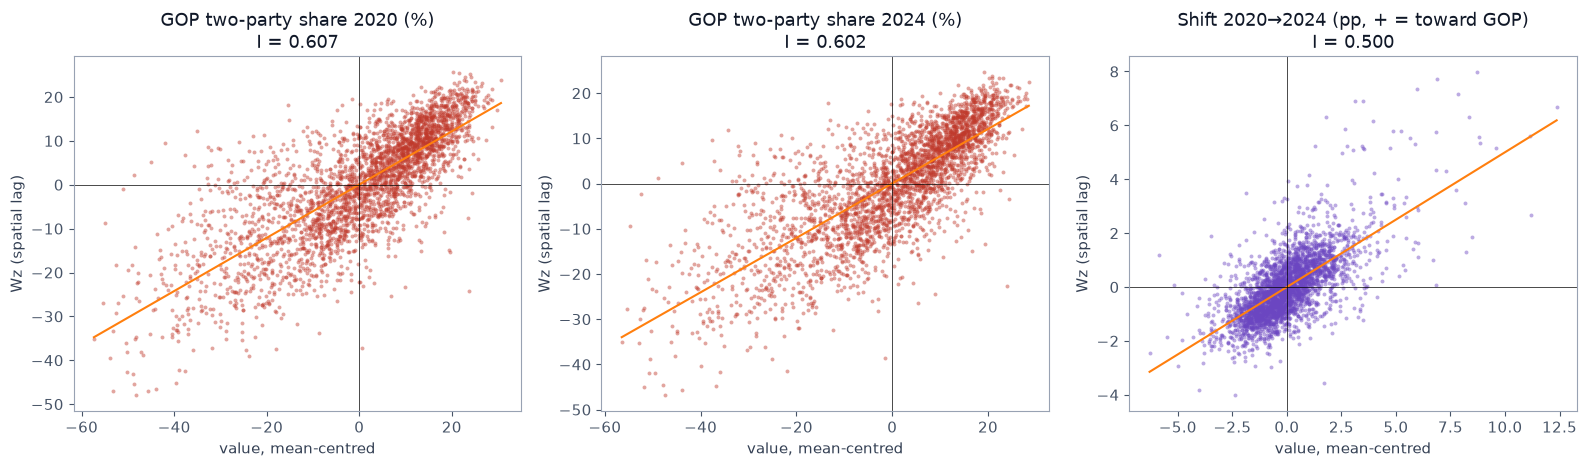

Moran's I is **0.607** in 2020 and **0.602** in 2024: the level of clustering in the vote geography is essentially unchanged. The shift itself has I = **0.500** (permutation p = 0.001). The 2024 change was regionally organised, not a uniform swing plus noise.

In [9]:
morans = {o: Moran(counties[o].to_numpy(float), w, permutations=PERM, seed=SEED) for o in OUTCOMES}
moran_tbl = pd.DataFrame({
    OUTCOMES[o]: {"I": m.I, "E[I]": m.get("expected_I"), "z": m.z_score, "p_sim": m.p_value}
    for o, m in morans.items()
}).T
display(moran_tbl.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (o, m), color in zip(axes, morans.items(), [COLORS["red"], COLORS["red"], COLORS["purple"]]):
    moran_scatter(m, ax=ax, s=8, c=color, alpha=0.45, linewidths=0)
    ax.set_title(f"{OUTCOMES[o]}\nI = {m.I:.3f}")
    ax.set_xlabel("value, mean-centred")
plt.tight_layout()
# ALT: Three Moran scatterplots for 2020 share, 2024 share, and the 2020-to-2024 shift, all with clearly positive slopes.
plt.show()

display(Markdown(
    f"Moran's I is **{morans['rep2p_2020'].I:.3f}** in 2020 and **{morans['rep2p_2024'].I:.3f}** in 2024: "
    f"the level of clustering in the vote geography is essentially unchanged. "
    f"The shift itself has I = **{morans['shift'].I:.3f}** (permutation p = {morans['shift'].p_value:.3f}). "
    f"The 2024 change was regionally organised, not a uniform swing plus noise."
))

## Local Clusters: What Persisted, What Moved

**LISA in each year.** We run Local Moran on 2020 and on 2024 separately and cross-tabulate the labels. Counties that are high-high (HH) in both years are the **persistent Republican core**; low-high (LL) in both years is the **persistent Democratic core**. Off-diagonal cells are counties that entered or left a cluster.

**Clusters of change.** Gi* and LISA on the shift itself show where neighbouring counties moved together.

In [10]:
lisa = {o: local_moran_clusters(counties[o].to_numpy(float), w, permutations=PERM,
                                correction="none", alpha=ALPHA, seed=SEED) for o in OUTCOMES}
for o in OUTCOMES:
    counties[f"lisa_{o}"] = lisa[o].labels

transition = pd.crosstab(
    counties["lisa_rep2p_2020"].rename("LISA 2020"),
    counties["lisa_rep2p_2024"].rename("LISA 2024"),
    margins=True,
)
display(transition)

hh20, hh24 = counties["lisa_rep2p_2020"] == "HH", counties["lisa_rep2p_2024"] == "HH"
ll20, ll24 = counties["lisa_rep2p_2020"] == "LL", counties["lisa_rep2p_2024"] == "LL"


def persistence_type(a, b):
    """Name the 2020→2024 transition of one county's LISA label."""
    if a == b == "HH":
        return "Persistent HH (GOP core)"
    if a == b == "LL":
        return "Persistent LL (Dem core)"
    if b == "HH":
        return "Entered HH"
    if a == "HH":
        return "Left HH"
    if b == "LL":
        return "Entered LL"
    if a == "LL":
        return "Left LL"
    return "Not clustered / other"


counties["persistence"] = [persistence_type(a, b) for a, b in
                           zip(counties["lisa_rep2p_2020"], counties["lisa_rep2p_2024"])]
display(counties["persistence"].value_counts().to_frame("counties"))
n_changed = int((counties["lisa_rep2p_2020"] != counties["lisa_rep2p_2024"]).sum())
display(Markdown(
    f"Jaccard(HH 2020, HH 2024) = **{jaccard(hh20.to_numpy(), hh24.to_numpy()):.2f}** and "
    f"Jaccard(LL 2020, LL 2024) = **{jaccard(ll20.to_numpy(), ll24.to_numpy()):.2f}**. "
    f"Only **{n_changed}** of {len(counties)} counties carry a different LISA label in 2024 than in 2020. "
    f"Cluster membership is overwhelmingly persistent."
))

LISA 2024,HH,HL,LH,LL,Not significant,All
LISA 2020,,,,,,
HH,511,0,1,0,24,536
HL,0,12,0,3,1,16
LH,1,0,13,0,3,17
LL,0,1,0,348,30,379
Not significant,28,5,2,18,2096,2149
All,540,18,16,369,2154,3097


,counties
persistence,
Not clustered / other,2132
Persistent HH (GOP core),511
Persistent LL (Dem core),348
Left LL,31
Entered HH,29
Left HH,25
Entered LL,21


Jaccard(HH 2020, HH 2024) = **0.90** and Jaccard(LL 2020, LL 2024) = **0.87**. Only **117** of 3097 counties carry a different LISA label in 2024 than in 2020. Cluster membership is overwhelmingly persistent.

,Gi* hot (shift),LISA HH (shift),Persistent GOP core,Persistent Dem core
Gi* hot (shift),1.000,0.744,0.000,0.163
LISA HH (shift),0.744,1.000,0.001,0.160
Persistent GOP core,0.000,0.001,1.000,0.000
Persistent Dem core,0.163,0.160,0.000,1.000


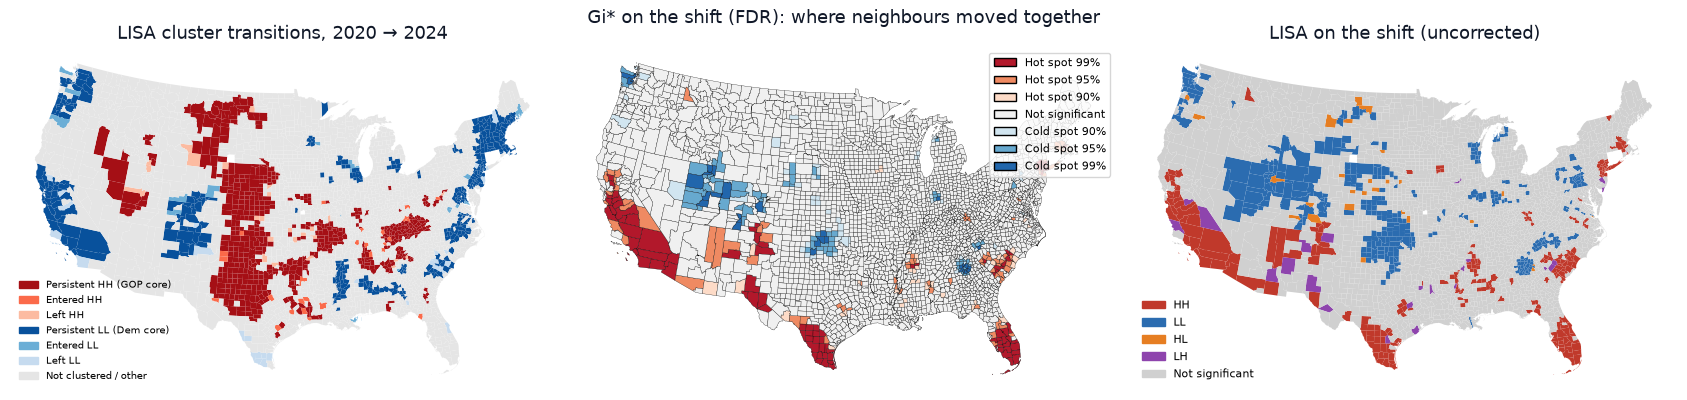

,counties,mean_shift,rep2p_2020,pct_hispanic
persistence,,,,
Left LL,31,4.85,48.32,37.65
Entered HH,29,2.66,76.97,13.58
Persistent LL (Dem core),348,2.36,41.68,13.23
Not clustered / other,2132,1.70,66.43,8.36
Persistent HH (GOP core),511,1.11,82.74,12.17
Left HH,25,0.39,80.27,7.04
Entered LL,21,0.34,50.16,12.80


Gi* (FDR) marks **217** counties in hot spots of rightward shift and **153** in cold spots (smaller rightward shift or a leftward move). Shift hot spots overlap the persistent GOP core at Jaccard **0.00** but the persistent Democratic core at **0.16**: the places that moved most in 2024 are **not** the places that were already most Republican; more of them sit in the persistent Democratic core.

In [11]:
gi_shift = getis_ord_gi(dy, w, star=True, inference="analytic", permutations=0, correction="fdr", alpha=ALPHA)
counties["gi_shift"] = gi_shift.labels
hot = np.array([str(l).startswith("Hot") for l in gi_shift.labels])
cold = np.array([str(l).startswith("Cold") for l in gi_shift.labels])
hh_shift = counties["lisa_shift"].to_numpy() == "HH"

agree = agreement_matrix({
    "Gi* hot (shift)": hot,
    "LISA HH (shift)": hh_shift,
    "Persistent GOP core": (hh20 & hh24).to_numpy(),
    "Persistent Dem core": (ll20 & ll24).to_numpy(),
})
display(agree.round(3))

PERSIST_COLORS = {
    "Persistent HH (GOP core)": "#a50f15", "Entered HH": "#fb6a4a", "Left HH": "#fcbba1",
    "Persistent LL (Dem core)": "#08519c", "Entered LL": "#6baed6", "Left LL": "#c6dbef",
    "Not clustered / other": "#e5e5e5",
}
LISA_COLORS = {"HH": "#c0392b", "LL": "#2b6cb0", "HL": "#e67e22", "LH": "#8e44ad", "Not significant": "#d0d0d0"}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for lab, col in PERSIST_COLORS.items():                 # categorical map: one colour per transition type
    sub = counties[counties["persistence"] == lab]
    if len(sub):
        sub.plot(ax=axes[0], color=col, edgecolor="none")
axes[0].legend(handles=[Patch(color=c, label=l) for l, c in PERSIST_COLORS.items()],
               loc="lower left", fontsize=7, frameon=False)
axes[0].set_title("LISA cluster transitions, 2020 → 2024")

gi_shift.plot(counties, ax=axes[1])
axes[1].set_title("Gi* on the shift (FDR): where neighbours moved together")

for lab, col in LISA_COLORS.items():
    sub = counties[counties["lisa_shift"] == lab]
    if len(sub):
        sub.plot(ax=axes[2], color=col, edgecolor="none")
axes[2].legend(handles=[Patch(color=c, label=l) for l, c in LISA_COLORS.items()],
               loc="lower left", fontsize=8, frameon=False)
axes[2].set_title("LISA on the shift (uncorrected)")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
# ALT: Three CONUS maps: persistent and changing LISA clusters of GOP share (dark red Great Plains and Appalachian core, dark blue urban and Black Belt cores), Gi-star hot spots of rightward shift in South Texas, South Florida and the New York area, and LISA clusters of the shift.
plt.show()

shift_by_type = counties.groupby("persistence").agg(
    counties=("shift", "size"), mean_shift=("shift", "mean"),
    rep2p_2020=("rep2p_2020", "mean"), pct_hispanic=("pct_hispanic", "mean"),
).sort_values("mean_shift", ascending=False)
display(shift_by_type.round(2))
display(Markdown(
    f"Gi* (FDR) marks **{int(hot.sum())}** counties in hot spots of rightward shift and **{int(cold.sum())}** "
    f"in cold spots (smaller rightward shift or a leftward move). Shift hot spots overlap the persistent GOP core at "
    f"Jaccard **{jaccard(hot, (hh20 & hh24).to_numpy()):.2f}** but the persistent Democratic core at "
    f"**{jaccard(hot, (ll20 & ll24).to_numpy()):.2f}**: the places that moved most in 2024 are **not** the places "
    f"that were already most Republican; more of them sit in the persistent Democratic core."
))

### SKATER regions on level and change together

SKATER (minimum-spanning-tree regionalisation) partitions the map into contiguous regions that are homogeneous in **both** the 2020 level and the shift, both standardised. Each region then reads as a pair: "was it Republican?" and "did it move?"

,n,rep2p_2020,rep2p_2024,shift,hispanic,rural
skater,,,,,,
1,89,52.19,55.30,3.12,2.73,68.91
2,54,45.82,48.82,3.00,30.02,26.00
4,209,67.68,70.36,2.67,19.25,53.89
3,215,63.33,65.91,2.57,8.74,55.71
0,471,53.82,55.86,2.04,6.79,50.22
7,614,66.08,67.73,1.65,7.69,62.27
6,1386,73.11,74.35,1.24,10.19,62.45
5,59,51.98,52.40,0.42,14.39,41.43


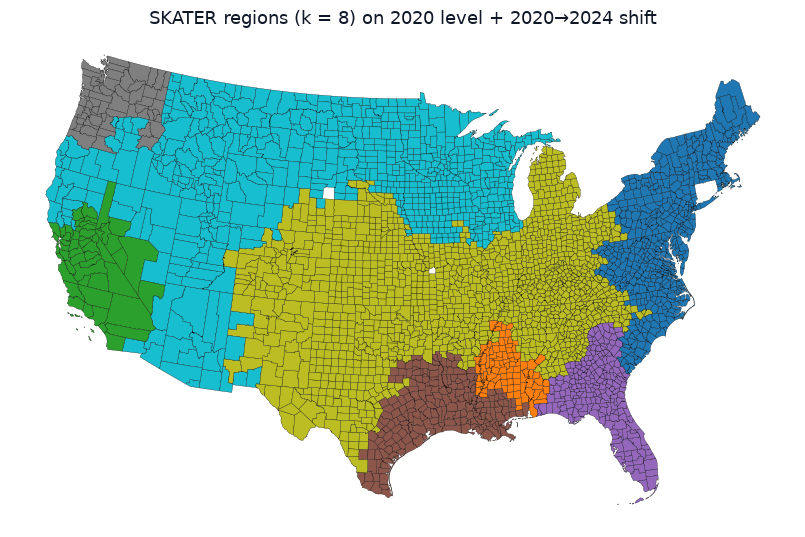

In [12]:
Z_ls = np.column_stack([(y20 - y20.mean()) / y20.std(), (dy - dy.mean()) / dy.std()])
regions = skater(Z_ls, w, n_clusters=8, min_size=50)
counties["skater"] = regions.labels

region_summary = (
    counties.groupby("skater")
    .agg(n=("shift", "size"), rep2p_2020=("rep2p_2020", "mean"), rep2p_2024=("rep2p_2024", "mean"),
         shift=("shift", "mean"), hispanic=("pct_hispanic", "mean"), rural=("pct_rural", "mean"))
    .round(2)
    .sort_values("shift", ascending=False)
)
display(region_summary)

fig, ax = plt.subplots(figsize=(9, 5.5))
regions.plot(counties, ax=ax, cmap="tab10", legend=False)
ax.set_axis_off()
ax.set_title("SKATER regions (k = 8) on 2020 level + 2020→2024 shift")
plt.tight_layout()
# ALT: CONUS map of eight contiguous SKATER regions grouping counties with similar 2020 GOP share and similar 2020-to-2024 shift.
plt.show()

## Explanation: Same Covariates, Three Outcomes

We fit **the same OLS** with standardised covariates to 2020 share, 2024 share, and the shift. Because the covariates are z-scores, each coefficient is "percentage points per one-SD difference across counties":

- A covariate with almost the same slope in 2020 and 2024 marks a **persistent** association.
- A covariate that matters for the shift but barely changes the level marks an association **specific to 2024**.

A fourth model adds 2020 share to the shift equation. Counties already near 80 % GOP have little room to move, so this separates ceiling effects from covariate effects.

,GOP two-party share 2020 (%),GOP two-party share 2024 (%),"Shift 2020→2024 (pp, + = toward GOP)",Shift | 2020 share
variable,,,,
const,66.258,67.958,1.700,1.700
pct_rural,3.745,3.905,0.160,0.284
pct_hispanic,-2.070,-1.440,0.630,0.561
pct_nh_black,-8.322,-7.986,0.336,0.060
pct_65plus,-0.275,-0.375,-0.100,-0.109
pct_some_college,-4.720,-4.715,0.006,-0.150
pct_unemployed,-4.303,-4.026,0.276,0.134
poverty_pctile,0.272,0.625,0.353,0.362
pop_change,0.262,0.251,-0.010,-0.002


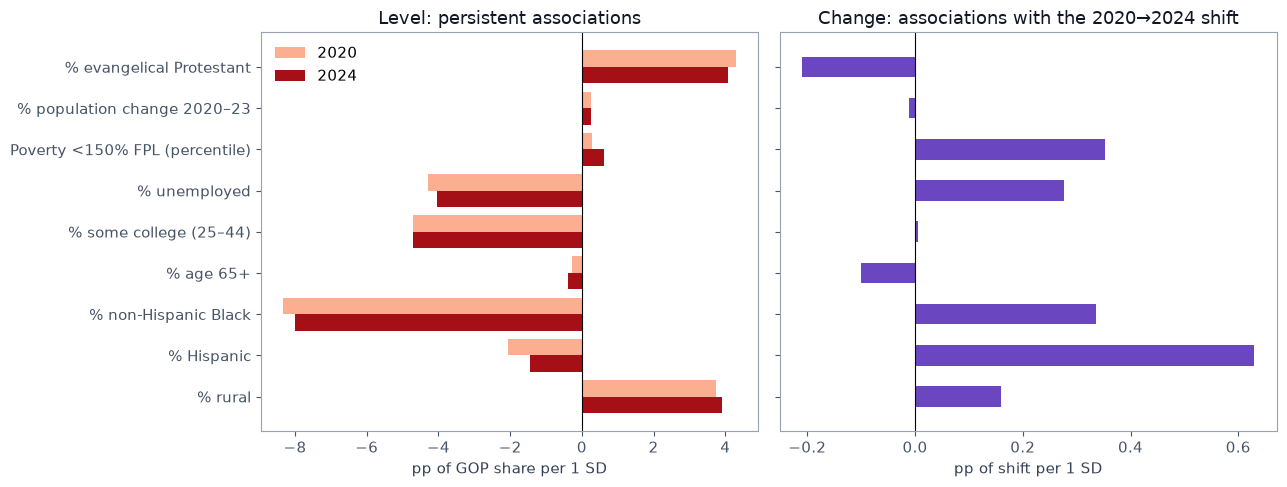

The level models explain R² = **0.62** (2020) and **0.62** (2024) with nearly the same slopes: the largest 2020→2024 change in any level slope is **0.63 pp** (for **% Hispanic**). The shift model explains R² = **0.31**, and its largest standardised slope is **% Hispanic** (+0.63 pp per SD), followed by Poverty <150% FPL (percentile) (+0.35), % non-Hispanic Black (+0.34), % unemployed (+0.28). Compare education and evangelical adherence: in 2024 their **level** slopes are -4.71 and +4.08, but their **shift** slopes are only +0.01 and -0.21. They describe the persistent map, not what changed in 2024.

In [13]:
y_vec = {o: counties[o].to_numpy(dtype=float) for o in OUTCOMES}
ols = {o: OLS(y_vec[o], X, w=w, y_name=o, names=COVARS) for o in OUTCOMES}

z20 = ((y20 - y20.mean()) / y20.std()).reshape(-1, 1)
ols_cond = OLS(dy, np.hstack([X, z20]), w=w, y_name="shift", names=COVARS + ["rep2p_2020"])


def coef_series(model):
    cf = model.coef_frame().set_index("variable")
    return cf["coef"], cf["p_value"]


coef_tbl = pd.DataFrame({OUTCOMES[o]: coef_series(m)[0] for o, m in ols.items()})
coef_tbl["Shift | 2020 share"] = coef_series(ols_cond)[0]
pval_tbl = pd.DataFrame({OUTCOMES[o]: coef_series(m)[1] for o, m in ols.items()})
pval_tbl["Shift | 2020 share"] = coef_series(ols_cond)[1]
coef_tbl.loc["R²"] = [ols[o].r2 for o in OUTCOMES] + [ols_cond.r2]
display(coef_tbl.round(3))

# Coefficient comparison plot: 2020 vs 2024 slopes (left), shift slopes (right).
cov_idx = np.arange(len(COVARS))
labels = [COVAR_LABELS[c] for c in COVARS]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(cov_idx + 0.2, coef_tbl.loc[COVARS, OUTCOMES["rep2p_2020"]], height=0.4,
             color="#fcae91", label="2020")
axes[0].barh(cov_idx - 0.2, coef_tbl.loc[COVARS, OUTCOMES["rep2p_2024"]], height=0.4,
             color="#a50f15", label="2024")
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_yticks(cov_idx, labels)
axes[0].set_xlabel("pp of GOP share per 1 SD")
axes[0].set_title("Level: persistent associations")
axes[0].legend(frameon=False)
axes[1].barh(cov_idx, coef_tbl.loc[COVARS, OUTCOMES["shift"]], height=0.5, color=COLORS["purple"])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("pp of shift per 1 SD")
axes[1].set_title("Change: associations with the 2020→2024 shift")
plt.tight_layout()
# ALT: Left, paired horizontal bars of OLS slopes for 2020 and 2024 GOP share that are nearly identical; right, slopes for the shift, led by Hispanic share, poverty, Black share and unemployment.
plt.show()

d_slope = (coef_tbl.loc[COVARS, OUTCOMES["rep2p_2024"]] - coef_tbl.loc[COVARS, OUTCOMES["rep2p_2020"]])
shift_slopes = coef_tbl.loc[COVARS, OUTCOMES["shift"]]
shift_rank = shift_slopes.abs().sort_values(ascending=False).index.tolist()   # covariates by |slope| on the shift
lead = shift_rank[0]
level_24 = coef_tbl.loc[COVARS, OUTCOMES["rep2p_2024"]]
display(Markdown(
    f"The level models explain R² = **{ols['rep2p_2020'].r2:.2f}** (2020) and **{ols['rep2p_2024'].r2:.2f}** (2024) "
    f"with nearly the same slopes: the largest 2020→2024 change in any level slope is "
    f"**{d_slope.abs().max():.2f} pp** (for **{COVAR_LABELS[d_slope.abs().idxmax()]}**). "
    f"The shift model explains R² = **{ols['shift'].r2:.2f}**, and its largest standardised slope is "
    f"**{COVAR_LABELS[lead]}** ({shift_slopes[lead]:+.2f} pp per SD), followed by "
    f"{', '.join(f'{COVAR_LABELS[c]} ({shift_slopes[c]:+.2f})' for c in shift_rank[1:4])}. "
    f"Compare education and evangelical adherence: in 2024 their **level** slopes are "
    f"{level_24['pct_some_college']:+.2f} and {level_24['pct_evangelical']:+.2f}, but their **shift** slopes are only "
    f"{shift_slopes['pct_some_college']:+.2f} and {shift_slopes['pct_evangelical']:+.2f}. "
    f"They describe the persistent map, not what changed in 2024."
))

### Spatial dependence in the residuals: LM tests, SLM, and SEM

Each OLS above ignores neighbours. Lagrange-multiplier tests on its residuals recommend a spatial lag (SLM) or spatial error (SEM) model. We fit both for every outcome and keep the lower AIC.

In [14]:
rows, spatial_fits = [], {}
for o in OUTCOMES:
    lm = ols[o].lm_tests(alpha=ALPHA)
    slm = SpatialLag(y_vec[o], X, w, y_name=o, names=COVARS)
    sem = SpatialError(y_vec[o], X, w, y_name=o, names=COVARS)
    cmp = compare_models({"OLS": ols[o], "SLM": slm, "SEM": sem})
    best = cmp["aic"].idxmin()
    spatial_fits[o] = {"OLS": ols[o], "SLM": slm, "SEM": sem, "best": best, "cmp": cmp}
    rows.append({
        "outcome": OUTCOMES[o], "LM recommends": lm.recommendation(), "best (AIC)": best,
        "AIC OLS": cmp.loc["OLS", "aic"], "AIC best": cmp.loc[best, "aic"],
        "SLM ρ": slm.rho, "SEM λ": sem.lam,
        "resid I (OLS)": cmp.loc["OLS", "resid_moran_I"], "resid I (best)": cmp.loc[best, "resid_moran_I"],
    })
spatial_tbl = pd.DataFrame(rows).set_index("outcome")
display(spatial_tbl.round(3))

best_shift = spatial_fits["shift"][spatial_fits["shift"]["best"]]
display(Markdown(
    f"For every outcome a spatial model beats OLS. For the shift, **{spatial_fits['shift']['best']}** wins "
    f"(SEM λ = {spatial_fits['shift']['SEM'].lam:.2f}, SLM ρ = {spatial_fits['shift']['SLM'].rho:.2f}), "
    f"and residual Moran's I falls from **{spatial_tbl.loc[OUTCOMES['shift'], 'resid I (OLS)']:.3f}** to "
    f"**{spatial_tbl.loc[OUTCOMES['shift'], 'resid I (best)']:.3f}**. Much of what the covariates "
    f"miss about the 2024 move is shared by neighbouring counties (state campaigns, media markets, local economies)."
))

,LM recommends,best (AIC),AIC OLS,AIC best,SLM ρ,SEM λ,resid I (OLS),resid I (best)
outcome,,,,,,,,
GOP two-party share 2020 (%),Spatial error model (both robust tests signifi...,SEM,23020.118,21081.214,0.554,0.839,0.492,-0.067
GOP two-party share 2024 (%),Spatial error model (both robust tests signifi...,SEM,22872.022,20996.378,0.556,0.838,0.482,-0.066
"Shift 2020→2024 (pp, + = toward GOP)",Spatial error model,SEM,10818.609,9608.320,0.587,0.692,0.445,-0.038


For every outcome a spatial model beats OLS. For the shift, **SEM** wins (SEM λ = 0.69, SLM ρ = 0.59), and residual Moran's I falls from **0.445** to **-0.038**. Much of what the covariates miss about the 2024 move is shared by neighbouring counties (state campaigns, media markets, local economies).

## Heterogeneity: Where Do the Shift Associations Change Sign?

A single national slope for Hispanic share or poverty can hide regional differences. Adaptive GWR estimates a local slope at every county. We choose the neighbour count $k$ by AICc on a coarse grid and map all nine local slopes **for the shift**.

Then we refit GWR at the same $k$ for 2020 and for 2024 and compare the local **Hispanic-share** slope between the two years. Where that slope rose, the Hispanic–Republican association changed in 2024.

In [15]:
gwr_rows, gwr_fits = [], {}
for k in (100, 200, 400):                       # coarse adaptive-bandwidth grid (each fit ≈ 1 min)
    fit = GWR(bandwidth=k, fixed=False, kernel="bisquare", criterion="AICc", hat_matrix=True, n_jobs=-1)
    fit.fit(X, dy, coords)
    gwr_fits[k] = fit
    gwr_rows.append({"k": k, "aicc": fit.aicc_, "rmse": float(np.sqrt(np.mean(fit.residuals_ ** 2)))})
gwr_grid = pd.DataFrame(gwr_rows).sort_values("aicc").reset_index(drop=True)
display(gwr_grid.round(2))
best_k = int(gwr_grid.loc[0, "k"])
gwr = gwr_fits[best_k]

for j, col in enumerate(COVARS):                # column 0 of coef_ is the intercept
    counties[f"gwr_{col}"] = gwr.coef_[:, 1 + j]

focus = "pct_hispanic"
local_focus = gwr.coef_[:, 1 + COVARS.index(focus)]
local_p = gwr.p_values_[:, 1 + COVARS.index(focus)]
display(Markdown(
    f"Lowest AICc at **k = {best_k}** neighbours (AICc {gwr.aicc_:.1f}, in-sample RMSE "
    f"{gwr_grid.loc[0, 'rmse']:.2f} pp vs OLS {np.sqrt(np.mean(np.asarray(ols['shift'].residuals) ** 2)):.2f} pp). "
    f"The local **{COVAR_LABELS[focus]}** slope on the shift runs from **{local_focus.min():.2f}** to "
    f"**{local_focus.max():.2f}** pp per SD (median {np.median(local_focus):.2f}); "
    f"**{(local_p < ALPHA).mean() * 100:.0f}%** of counties have an uncorrected local p < {ALPHA}."
))

,k,aicc,rmse
0,100,2904.23,0.81
1,200,3187.88,0.94
2,400,3625.22,1.05


Lowest AICc at **k = 100** neighbours (AICc 2904.2, in-sample RMSE 0.81 pp vs OLS 1.38 pp). The local **% Hispanic** slope on the shift runs from **-3.52** to **3.41** pp per SD (median 0.53); **25%** of counties have an uncorrected local p < 0.05.

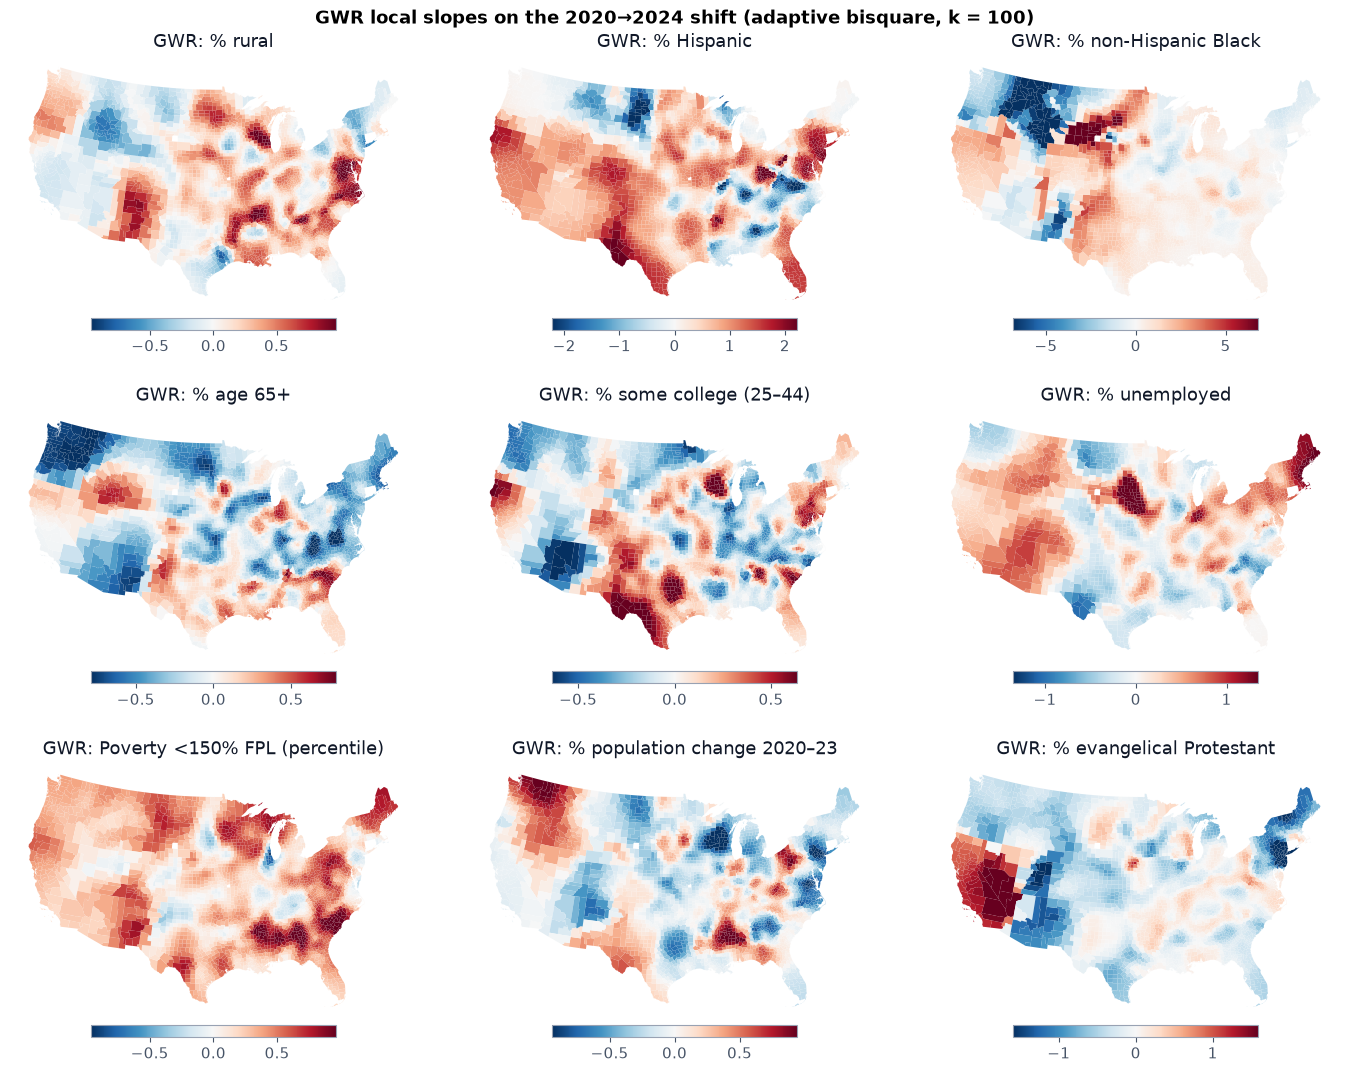

In [16]:
# 3 × 3 grid of local GWR slopes on the shift (one panel per covariate).
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, col in zip(axes.ravel(), COVARS):
    vals = counties[f"gwr_{col}"]                        # local slope written after the GWR fit
    lim = float(np.nanpercentile(np.abs(vals), 98))      # symmetric colour limits around zero
    counties.plot(
        column=f"gwr_{col}",
        cmap="RdBu_r",                                   # red = covariate linked to a larger rightward shift
        norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
        legend=True, ax=ax, edgecolor="none",
        legend_kwds={"shrink": 0.55, "orientation": "horizontal", "pad": 0.02},
    )
    ax.set_axis_off()
    ax.set_title(f"GWR: {COVAR_LABELS[col]}")
plt.suptitle(f"GWR local slopes on the 2020→2024 shift (adaptive bisquare, k = {best_k})",
             fontsize=13, fontweight="bold")
plt.tight_layout()
# ALT: Nine CONUS maps of GWR local slopes on the GOP shift; the Hispanic-share slope is positive across the West, Texas, Florida and the Northeast and negative in the northern Plains and parts of the Southeast.
plt.show()

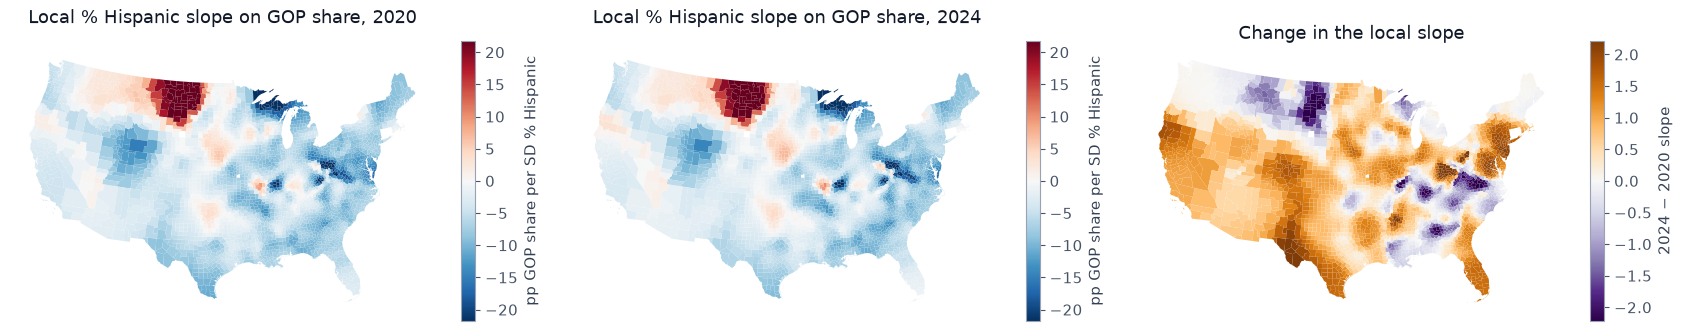

The local Hispanic-share slope rose (became more Republican) in **71%** of counties; median change **+0.53** pp per SD. The local slope keeps its 2020 sign in **97%** of counties. The same persistence/change split shows up inside a single relationship: the geography of the association carries over, while its strength moved toward the GOP.

In [17]:
# Same adaptive bandwidth for both years so the two slope surfaces are directly comparable.
gwr_year = {}
for yr in YEARS:
    f = GWR(bandwidth=best_k, fixed=False, kernel="bisquare", criterion="AICc", hat_matrix=False, n_jobs=-1)
    f.fit(X, y_vec[f"rep2p_{yr}"], coords)
    gwr_year[yr] = f.coef_[:, 1 + COVARS.index(focus)]
counties["gwr_hisp_2020"] = gwr_year[2020]
counties["gwr_hisp_2024"] = gwr_year[2024]
counties["gwr_hisp_change"] = gwr_year[2024] - gwr_year[2020]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
lim_lvl = float(np.nanpercentile(np.abs(np.r_[gwr_year[2020], gwr_year[2024]]), 98))
for ax, col, title in zip(axes[:2], ["gwr_hisp_2020", "gwr_hisp_2024"], ["2020", "2024"]):
    counties.plot(column=col, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim_lvl, vcenter=0, vmax=lim_lvl),
                  legend=True, ax=ax, edgecolor="none",
                  legend_kwds={"shrink": 0.6, "label": "pp GOP share per SD % Hispanic"})
    ax.set_title(f"Local % Hispanic slope on GOP share, {title}")
lim_chg = float(np.nanpercentile(np.abs(counties["gwr_hisp_change"]), 98))
counties.plot(column="gwr_hisp_change", cmap="PuOr_r", norm=TwoSlopeNorm(vmin=-lim_chg, vcenter=0, vmax=lim_chg),
              legend=True, ax=axes[2], edgecolor="none",
              legend_kwds={"shrink": 0.6, "label": "2024 − 2020 slope"})
axes[2].set_title("Change in the local slope")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
# ALT: Three CONUS maps of the local GWR slope of GOP share on Hispanic share in 2020 and 2024 and their difference; the 2020 and 2024 surfaces look alike, and the change map shows the slope rising across the West, Texas, Florida and the Northeast and falling in the northern Plains and parts of the Southeast.
plt.show()
display(Markdown(
    f"The local Hispanic-share slope rose (became more Republican) in **{(counties['gwr_hisp_change'] > 0).mean() * 100:.0f}%** "
    f"of counties; median change **{counties['gwr_hisp_change'].median():+.2f}** pp per SD. "
    f"The local slope keeps its 2020 sign in **{(np.sign(gwr_year[2020]) == np.sign(gwr_year[2024])).mean() * 100:.0f}%** "
    f"of counties. The same persistence/change split shows up inside a single relationship: the geography of the "
    f"association carries over, while its strength moved toward the GOP."
))

In [18]:
# Fixed-kernel MGWR on the shift: one bandwidth per column (intercept + nine covariates).
bw0 = 250_000  # metres
mgwr = MGWR(
    bw_init=[bw0] * (1 + len(COVARS)),
    kernel="bisquare", fixed=True, criterion="AICc",
    tol=1.0, max_iter=4, bw_tol=25_000, n_jobs=-1,
)
mgwr.fit(X, dy, coords)
bw_km = pd.Series(mgwr.bandwidths_ / 1000, index=["Intercept", *COVARS], name="bandwidth_km")
display(pd.concat([
    bw_km,
    pd.Series(gwr.coef_.std(axis=0), index=bw_km.index, name="gwr_sd"),
    pd.Series(mgwr.coef_.std(axis=0), index=bw_km.index, name="mgwr_sd"),
], axis=1).round(2))
if float(bw_km.max() - bw_km.min()) < 1:
    bw_sentence = (f"All bandwidths settled at **{bw_km.max():.0f} km**; on this coarse fixed-kernel search the "
                   f"covariates do not separate in spatial scale.")
else:
    bw_sentence = (f"The widest bandwidth is **{bw_km.idxmax()}** ({bw_km.max():.0f} km) and the narrowest "
                   f"**{bw_km.idxmin()}** ({bw_km.min():.0f} km).")
display(Markdown(f"MGWR AICc on the shift is **{mgwr.aicc_:.1f}** against adaptive GWR **{gwr.aicc_:.1f}**. {bw_sentence}"))

,bandwidth_km,gwr_sd,mgwr_sd
Intercept,316.77,1.47,0.62
pct_rural,316.77,0.33,0.31
pct_hispanic,316.77,0.92,0.49
pct_nh_black,316.77,2.03,0.55
pct_65plus,316.77,0.33,0.22
pct_some_college,316.77,0.28,0.21
pct_unemployed,316.77,0.46,0.24
poverty_pctile,316.77,0.29,0.18
pop_change,316.77,0.38,0.26
pct_evangelical,316.77,0.51,0.24


MGWR AICc on the shift is **2273.4** against adaptive GWR **2904.2**. All bandwidths settled at **317 km**; on this coarse fixed-kernel search the covariates do not separate in spatial scale.

## Was the Shift Real? A Count Model Against a "Kept-2020" Expectation

A 3-point shift in a county with 300 ballots is not the same evidence as a 3-point shift in one with 300,000. We treat **2024 Republican votes** as counts and set the expectation to the votes the county would have cast if it had **kept its 2020 two-party share**:

$$E_i = \frac{\text{rep2p}_{2020,i}}{100}\,(\text{Rep}_{2024,i} + \text{Dem}_{2024,i}).$$

- **SMR** = observed / expected. Values above 1 mean the county moved toward the GOP.
- **Empirical Bayes** shrinks unstable small-county SMRs toward the national ratio.
- **BYM** adds a spatial CAR effect and gives each county a posterior probability that it really moved right, $P(\theta_i > 1)$.

This is not a turnout or persuasion model. It is a precision-aware map of the shift.

,mean,std,min,max
SMR,1.0311,0.0419,0.8842,1.7041
EB,1.0312,0.0374,0.8862,1.6959
BYM,1.0307,0.0380,0.8882,1.6970


,mean,sd,q_lo,q_hi,rhat,ess
parameter,,,,,,
intercept,0.030,0.000,0.029,0.030,0.999,354.655
tau_u,514.431,26.800,464.054,570.893,1.017,199.450
tau_v,4896.579,408.947,4152.680,5690.230,1.008,178.606


National SMR (sum observed / sum expected) = **1.0492**. SMR SD **0.0419** becomes **0.0374** after EB and **0.0380** after BYM. In the smallest fifth of counties the mean EB weight on the county's own data is **0.66** against **0.93** elsewhere. **1906** of 3097 counties have P(θ > 1) > 0.95 (a credible rightward move) and **75** have P(θ > 1) < 0.05 (a credible leftward move). BYM max R-hat **1.049**, min ESS **48**.

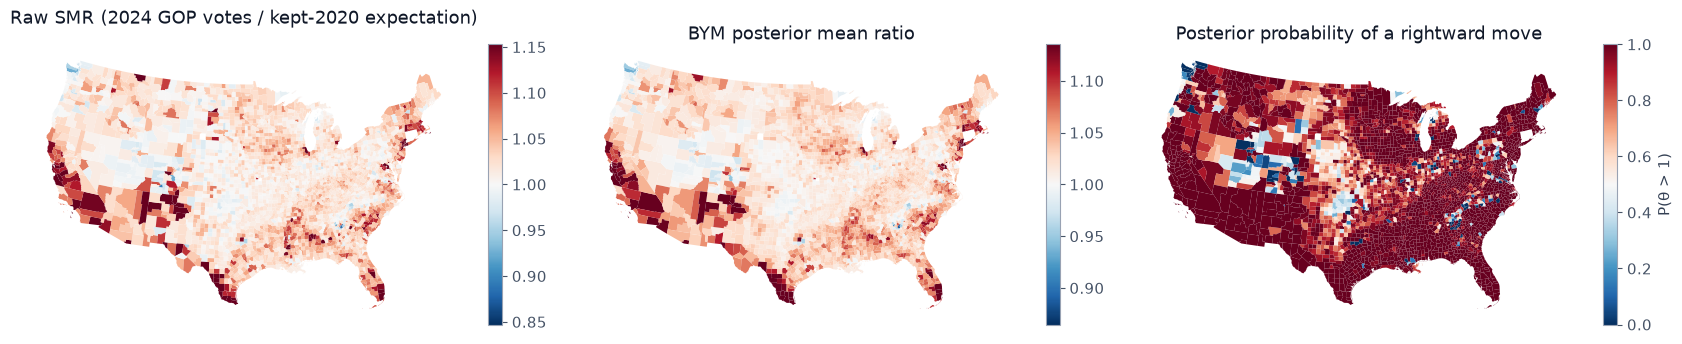

In [19]:
observed = counties["rep_2024"].to_numpy(dtype=float)
expected = (y20 / 100) * ballots
raw_smr = smr(observed, expected)
eb = eb_gamma_poisson(observed, expected, method="mle", alpha=ALPHA)
bym = BYM(observed, expected, w, backend="gibbs", draws=400, tune=400, chains=2, thin=5, seed=SEED, alpha=ALPHA)

counties["smr"] = raw_smr
counties["eb"] = eb.estimate
counties["rr"] = bym.rr_mean
counties["p_right"] = bym.exceedance(1.0)

display(pd.DataFrame({"SMR": raw_smr, "EB": eb.estimate, "BYM": bym.rr_mean})
        .agg(["mean", "std", "min", "max"]).T.round(4))
display(bym.diagnostics.round(3))
small = ballots <= np.quantile(ballots, 0.2)
display(Markdown(
    f"National SMR (sum observed / sum expected) = **{observed.sum() / expected.sum():.4f}**. "
    f"SMR SD **{raw_smr.std():.4f}** becomes **{eb.estimate.std():.4f}** after EB and **{bym.rr_mean.std():.4f}** after BYM. "
    f"In the smallest fifth of counties the mean EB weight on the county's own data is **{eb.shrinkage[small].mean():.2f}** "
    f"against **{eb.shrinkage[~small].mean():.2f}** elsewhere. "
    f"**{(counties['p_right'] > 0.95).sum()}** of {len(counties)} counties have P(θ > 1) > 0.95 (a credible rightward move) and "
    f"**{(counties['p_right'] < 0.05).sum()}** have P(θ > 1) < 0.05 (a credible leftward move). "
    f"BYM max R-hat **{bym.max_rhat:.3f}**, min ESS **{bym.min_ess:.0f}**."
))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, title in zip(axes[:2], ["smr", "rr"], ["Raw SMR (2024 GOP votes / kept-2020 expectation)",
                                                     "BYM posterior mean ratio"]):
    vals = counties[col]
    lim = float(np.nanpercentile(np.abs(vals - 1), 98))
    counties.plot(column=col, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=1 - lim, vcenter=1, vmax=1 + lim),
                  legend=True, ax=ax, edgecolor="none", legend_kwds={"shrink": 0.6})
    ax.set_title(title)
counties.plot(column="p_right", cmap="RdBu_r", vmin=0, vmax=1, legend=True, ax=axes[2], edgecolor="none",
              legend_kwds={"shrink": 0.6, "label": "P(θ > 1)"})
axes[2].set_title("Posterior probability of a rightward move")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
# ALT: Three CONUS maps of 2024 GOP votes relative to a kept-2020-share expectation: raw ratio, BYM-smoothed ratio, and the probability the county moved right, which is near 1 across most of the country.
plt.show()

## Machine-Learning Cross-Check: XGBoost and TreeSHAP

The guideline suggests a random-forest/XGBoost model with SHAP explanations. Gradient-boosted trees can find non-linearities and interactions that OLS cannot, such as Hispanic share mattering more in poorer counties. Two choices keep the comparison honest:

- **Spatial cross-validation.** Folds are grouped **by state**, so the model is always scored on states it has never seen. Random folds would leak neighbouring counties between training and test sets.
- **TreeSHAP.** XGBoost's built-in `pred_contribs=True` returns per-county additive attributions with no extra package.

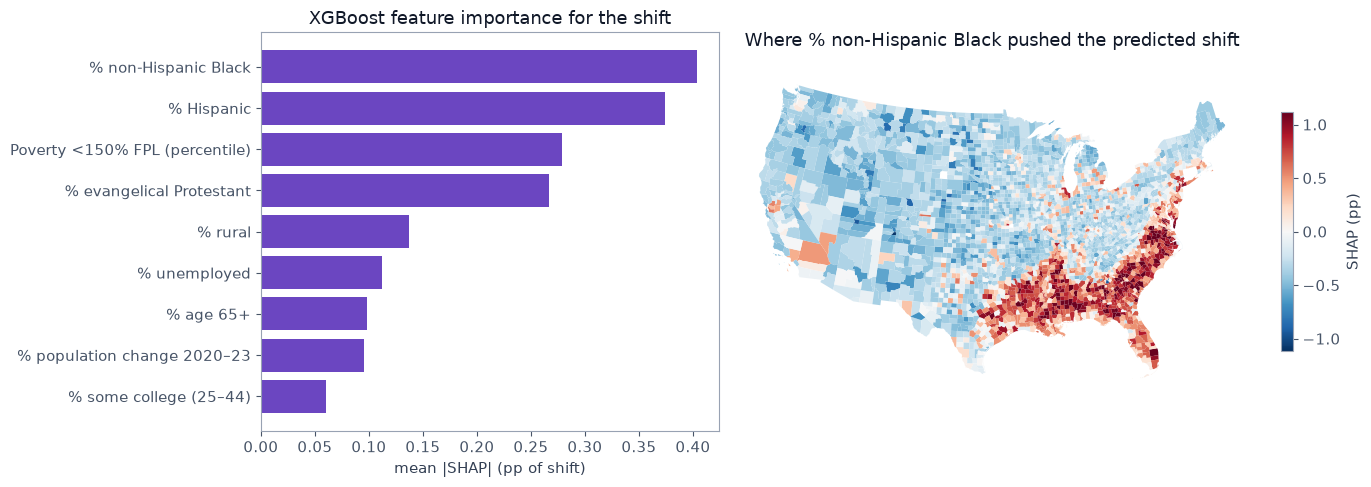

State-held-out R²: XGBoost **0.36** vs OLS **0.26**. TreeSHAP ranks **% non-Hispanic Black**, **% Hispanic**, **Poverty <150% FPL (percentile)** highest. OLS ranks **% Hispanic** first instead. A linear slope and a tree attribution share credit differently between correlated covariates, so read the two rankings together. Out-of-fold residuals still have Moran's I = **0.356** (p = 0.001). Even a flexible non-spatial learner leaves regionally shared structure in the shift, which is the case for the spatial models above.

In [20]:
import xgboost as xgb
from sklearn.model_selection import GroupKFold

params = dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
              colsample_bytree=0.8, random_state=SEED, n_jobs=-1)
groups = counties["STATE"].to_numpy()
oof = np.full(len(dy), np.nan)
for train, test in GroupKFold(n_splits=8).split(X_raw, dy, groups):     # whole states held out
    model = xgb.XGBRegressor(**params).fit(X_raw[train], dy[train])
    oof[test] = model.predict(X_raw[test])

ss_res = np.sum((dy - oof) ** 2)
r2_cv = 1 - ss_res / np.sum((dy - dy.mean()) ** 2)

# OLS scored the same way (state-grouped folds) for a like-for-like comparison.
oof_ols = np.full(len(dy), np.nan)
for train, test in GroupKFold(n_splits=8).split(X_raw, dy, groups):
    A = np.column_stack([np.ones(len(train)), X_raw[train]])
    beta, *_ = np.linalg.lstsq(A, dy[train], rcond=None)
    oof_ols[test] = np.column_stack([np.ones(len(test)), X_raw[test]]) @ beta
r2_cv_ols = 1 - np.sum((dy - oof_ols) ** 2) / np.sum((dy - dy.mean()) ** 2)

# Final model on all counties, then TreeSHAP contributions (last column = bias term).
xgb_model = xgb.XGBRegressor(**params).fit(X_raw, dy)
shap_vals = xgb_model.get_booster().predict(xgb.DMatrix(X_raw), pred_contribs=True)[:, :-1]
shap_imp = pd.Series(np.abs(shap_vals).mean(axis=0), index=[COVAR_LABELS[c] for c in COVARS]).sort_values()
for j, col in enumerate(COVARS):
    counties[f"shap_{col}"] = shap_vals[:, j]

# Spatial dependence the trees leave behind.
resid_ml = dy - oof
moran_ml = Moran(resid_ml, w, permutations=PERM, seed=SEED)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(shap_imp.index, shap_imp.values, color=COLORS["purple"])
axes[0].set_xlabel("mean |SHAP| (pp of shift)")
axes[0].set_title("XGBoost feature importance for the shift")
top_feat = COVARS[int(np.argmax(np.abs(shap_vals).mean(axis=0)))]
lim = float(np.nanpercentile(np.abs(counties[f"shap_{top_feat}"]), 98))
counties.plot(column=f"shap_{top_feat}", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
              legend=True, ax=axes[1], edgecolor="none", legend_kwds={"shrink": 0.6, "label": "SHAP (pp)"})
axes[1].set_axis_off()
axes[1].set_title(f"Where {COVAR_LABELS[top_feat]} pushed the predicted shift")
plt.tight_layout()
# ALT: Left, bar chart of mean absolute SHAP values for the nine covariates predicting the GOP shift; right, CONUS map of the SHAP contribution of the top covariate.
plt.show()

shap_top3 = ", ".join(f"**{lab}**" for lab in shap_imp.index[::-1][:3])
if top_feat == lead:
    rank_sentence = "Its top feature matches the lead covariate of the OLS shift model."
else:
    rank_sentence = (f"OLS ranks **{COVAR_LABELS[lead]}** first instead. A linear slope and a tree attribution "
                     f"share credit differently between correlated covariates, so read the two rankings together.")
display(Markdown(
    f"State-held-out R²: XGBoost **{r2_cv:.2f}** vs OLS **{r2_cv_ols:.2f}**. "
    f"TreeSHAP ranks {shap_top3} highest. {rank_sentence} "
    f"Out-of-fold residuals still have Moran's I = **{moran_ml.I:.3f}** (p = {moran_ml.p_value:.3f}). "
    f"Even a flexible non-spatial learner leaves regionally shared structure in the shift, which is the case "
    f"for the spatial models above."
))

## Decision Log and Summary Figure

Every modelling choice in one table, then a six-panel figure a reader can skim without re-running the notebook.

,choice,setting,reason
0,Data source,"Atlas SQLite (presidential_election_results, c...","One local, documented database; provenance in ..."
1,Years,"2020 (MEDSL) vs 2024 (tonmcg, provisional)",Separate persistent geography from 2024-specif...
2,Outcomes,"GOP two-party share 2020, 2024, and their diff...",Two-party share removes minor-party swings fro...
3,Covariates,"pct_rural, pct_hispanic, pct_nh_black, pct_65p...",Guideline priority list available in the Atlas...
4,Coverage rule,both years + all covariates,Drops Connecticut (2024 planning regions)
5,Comparability rule,"2024/2020 ballots in [0.67, 1.5]",Drops 1 county with a source boundary change (...
6,CRS / coordinates,EPSG:5070; polygon centroids,Audit passed; metres
7,Weights,"Queen, row-standardised, islands linked",Moran's I stable across KNN 4–12
8,Alpha / permutations / seed,0.05 / 999 / 7,Fixed for every test
9,Cluster transitions,"LISA (uncorrected) in each year, cross-tabulated",Same α both years


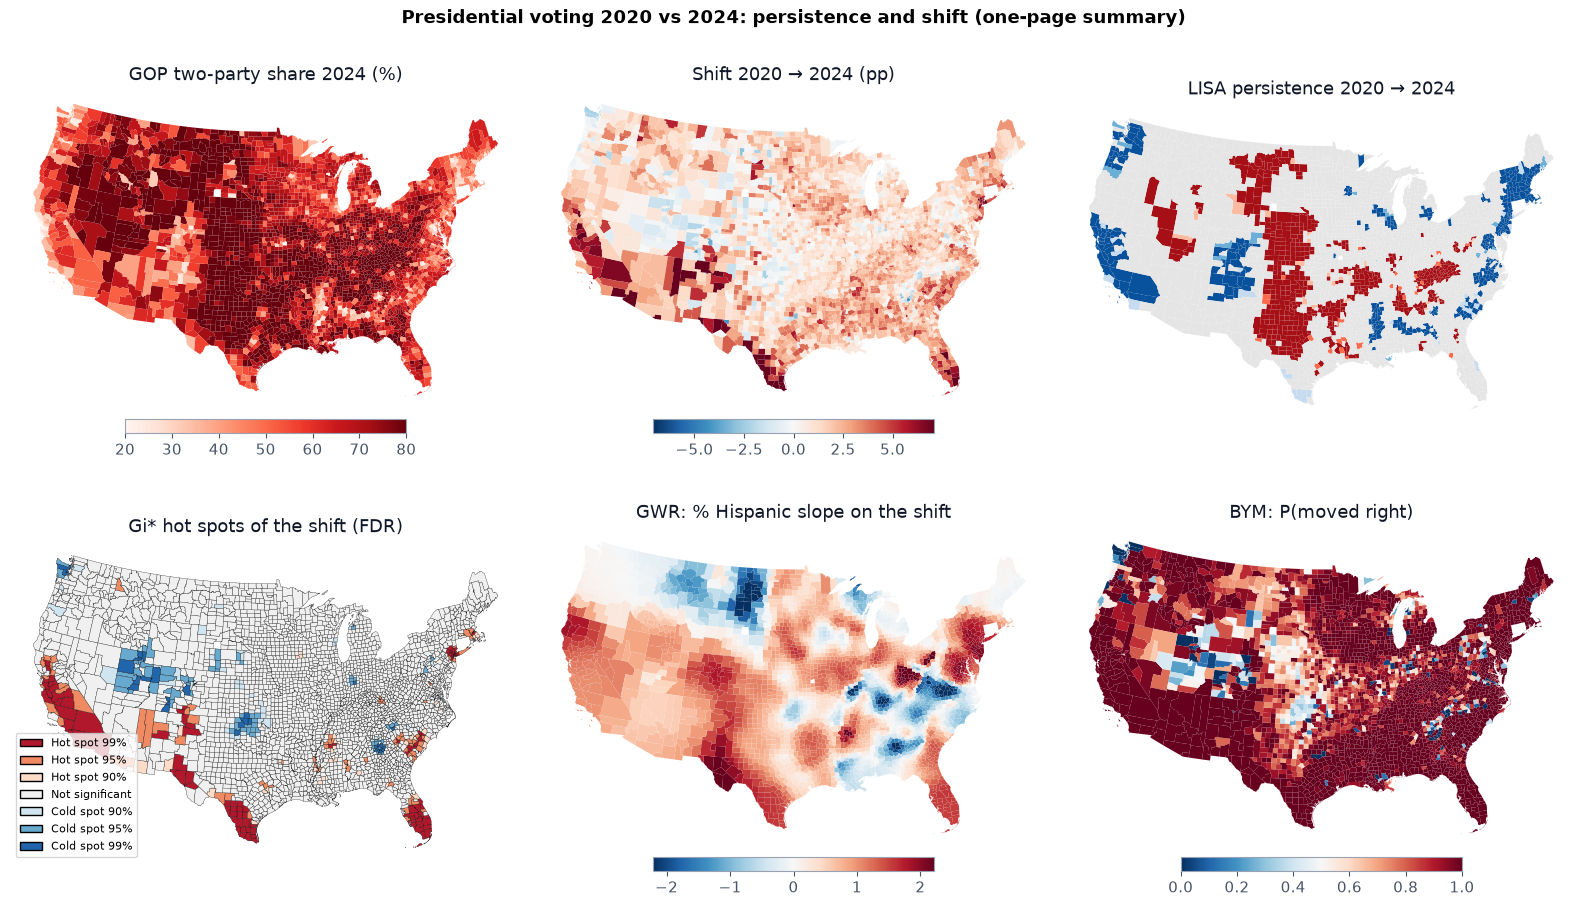

In [21]:
decisions = pd.DataFrame([
    {"choice": "Data source", "setting": "Atlas SQLite (presidential_election_results, county_indicators)",
     "reason": "One local, documented database; provenance in dataset_catalog / data_load_log"},
    {"choice": "Years", "setting": "2020 (MEDSL) vs 2024 (tonmcg, provisional)",
     "reason": "Separate persistent geography from 2024-specific change"},
    {"choice": "Outcomes", "setting": "GOP two-party share 2020, 2024, and their difference",
     "reason": "Two-party share removes minor-party swings from the shift"},
    {"choice": "Covariates", "setting": ", ".join(COVARS), "reason": "Guideline priority list available in the Atlas; z-scored"},
    {"choice": "Coverage rule", "setting": "both years + all covariates", "reason": "Drops Connecticut (2024 planning regions)"},
    {"choice": "Comparability rule", "setting": "2024/2020 ballots in [0.67, 1.5]",
     "reason": f"Drops {int(not_comparable.sum())} county with a source boundary change (Jackson Co., MO)"},
    {"choice": "CRS / coordinates", "setting": "EPSG:5070; polygon centroids", "reason": "Audit passed; metres"},
    {"choice": "Weights", "setting": "Queen, row-standardised, islands linked", "reason": "Moran's I stable across KNN 4–12"},
    {"choice": "Alpha / permutations / seed", "setting": f"{ALPHA} / {PERM} / {SEED}", "reason": "Fixed for every test"},
    {"choice": "Cluster transitions", "setting": "LISA (uncorrected) in each year, cross-tabulated", "reason": "Same α both years"},
    {"choice": "Shift clusters", "setting": "Gi* analytic with FDR; LISA uncorrected",
     "reason": "999-permutation LISA cannot pass FDR at n ≈ 3,100; Gi* carries the corrected map"},
    {"choice": "Mean model (shift)", "setting": spatial_fits["shift"]["best"], "reason": "Lowest AIC among OLS, SLM, SEM"},
    {"choice": "GWR", "setting": f"adaptive bisquare, k = {best_k}", "reason": "Lowest AICc on 100 / 200 / 400"},
    {"choice": "MGWR", "setting": "fixed bisquare, ≤ 4 iterations", "reason": "Adaptive MGWR is expensive at n ≈ 3,100"},
    {"choice": "Count model", "setting": "SMR → EB → BYM vs kept-2020 expectation", "reason": "400 draws, 400 tune, 2 chains, thin 5"},
    {"choice": "Machine learning", "setting": "XGBoost, 8 state-grouped folds, TreeSHAP", "reason": "Spatial CV avoids neighbour leakage"},
    {"choice": "Not fit", "setting": "IDW surface, space-time model",
     "reason": "Votes are areal, not a field; spacetime module is a stub (two time points here)"},
])
display(decisions)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
lim = float(np.nanpercentile(np.abs(dy), 99))
counties.plot(column="rep2p_2024", cmap="Reds", vmin=20, vmax=80, ax=axes[0, 0], edgecolor="none", legend=True,
              legend_kwds={"shrink": 0.55, "orientation": "horizontal", "pad": 0.02})
axes[0, 0].set_title("GOP two-party share 2024 (%)")
counties.plot(column="shift", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), ax=axes[0, 1],
              edgecolor="none", legend=True, legend_kwds={"shrink": 0.55, "orientation": "horizontal", "pad": 0.02})
axes[0, 1].set_title("Shift 2020 → 2024 (pp)")
for lab, col in PERSIST_COLORS.items():
    sub = counties[counties["persistence"] == lab]
    if len(sub):
        sub.plot(ax=axes[0, 2], color=col, edgecolor="none")
axes[0, 2].set_title("LISA persistence 2020 → 2024")
gi_shift.plot(counties, ax=axes[1, 0])
axes[1, 0].set_title("Gi* hot spots of the shift (FDR)")
leg = axes[1, 0].get_legend()
if leg is not None:
    leg.set_loc("lower left")
lim_h = float(np.nanpercentile(np.abs(counties["gwr_pct_hispanic"]), 98))
counties.plot(column="gwr_pct_hispanic", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim_h, vcenter=0, vmax=lim_h),
              ax=axes[1, 1], edgecolor="none", legend=True,
              legend_kwds={"shrink": 0.55, "orientation": "horizontal", "pad": 0.02})
axes[1, 1].set_title("GWR: % Hispanic slope on the shift")
counties.plot(column="p_right", cmap="RdBu_r", vmin=0, vmax=1, ax=axes[1, 2], edgecolor="none", legend=True,
              legend_kwds={"shrink": 0.55, "orientation": "horizontal", "pad": 0.02})
axes[1, 2].set_title("BYM: P(moved right)")
for ax in axes.ravel():
    ax.set_axis_off()
fig.suptitle("Presidential voting 2020 vs 2024: persistence and shift (one-page summary)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
# ALT: Six-panel CONUS summary: 2024 GOP share, the 2020-to-2024 shift, persistent and changing LISA clusters, Gi-star hot spots of the shift, the GWR Hispanic-share slope on the shift, and the BYM probability of a rightward move.
plt.show()

## Summary and Conclusions

In [22]:
display(Markdown(f'''
**Persistence.** Across **{len(counties)}** contiguous-US counties the partisan map barely moved. County GOP two-party share correlates at
**r = {r_persist:.3f}** between 2020 and 2024. Moran's I is **{morans["rep2p_2020"].I:.3f}** and **{morans["rep2p_2024"].I:.3f}**,
and LISA cluster membership carries over (Jaccard HH = **{jaccard(hh20.to_numpy(), hh24.to_numpy()):.2f}**, LL = **{jaccard(ll20.to_numpy(), ll24.to_numpy()):.2f}**).
The same covariates explain both years with nearly identical slopes (R² **{ols["rep2p_2020"].r2:.2f}** vs **{ols["rep2p_2024"].r2:.2f}**).
Rurality and evangelical adherence go with Republican support; college education, Black share, and unemployment go with Democratic support.
That is the durable geography.

**Change.** On top of that stable map, **{(dy > 0).mean() * 100:.0f}%** of counties moved toward the GOP (median **{np.median(dy):+.2f} pp**,
ballot-weighted **{weighted_shift:+.2f} pp**). The move was spatially organised: Moran's I of the shift is **{morans["shift"].I:.3f}**,
and Gi\\* marks **{int(hot.sum())}** hot-spot counties. Those hot spots do not coincide with the persistent GOP core
(Jaccard **{jaccard(hot, (hh20 & hh24).to_numpy()):.2f}**) and overlap more with the persistent Democratic core
(Jaccard **{jaccard(hot, (ll20 & ll24).to_numpy()):.2f}**). The shift's strongest correlate is **{COVAR_LABELS[lead]}**
({shift_slopes[lead]:+.2f} pp per SD), followed by {", ".join(COVAR_LABELS[c] for c in shift_rank[1:4])}.
Education and evangelical adherence, which carry the level models, have shift slopes of only
{shift_slopes["pct_some_college"]:+.2f} and {shift_slopes["pct_evangelical"]:+.2f}.
GWR shows the Hispanic-share association is far from uniform: its local slope on the shift runs from
**{local_focus.min():.2f}** to **{local_focus.max():.2f}** pp per SD, and between 2020 and 2024 the local Hispanic slope on GOP share
rose in **{(counties["gwr_hisp_change"] > 0).mean() * 100:.0f}%** of counties.

**Robustness.** A spatial model (**{spatial_fits["shift"]["best"]}**) beats OLS for every outcome. The count model against a
kept-2020 expectation gives **{(counties["p_right"] > 0.95).sum()}** counties a posterior probability above 0.95 of a real rightward move.
XGBoost scored on held-out states (R² **{r2_cv:.2f}** vs OLS **{r2_cv_ols:.2f}**) ranks {shap_top3} highest and still leaves
spatially autocorrelated residuals (I = **{moran_ml.I:.3f}**).

**Interpretation limits.** These are county-level associations (ecological fallacy). The 2024 returns are provisional and come from a
different compiler than 2020. The covariates describe places, not voters. Two elections are a comparison, not a trend:
`presidential_election_results` already holds 2004–2016 for a longer panel.
'''))


**Persistence.** Across **3097** contiguous-US counties the partisan map barely moved. County GOP two-party share correlates at
**r = 0.995** between 2020 and 2024. Moran's I is **0.607** and **0.602**,
and LISA cluster membership carries over (Jaccard HH = **0.90**, LL = **0.87**).
The same covariates explain both years with nearly identical slopes (R² **0.62** vs **0.62**).
Rurality and evangelical adherence go with Republican support; college education, Black share, and unemployment go with Democratic support.
That is the durable geography.

**Change.** On top of that stable map, **88%** of counties moved toward the GOP (median **+1.53 pp**,
ballot-weighted **+2.39 pp**). The move was spatially organised: Moran's I of the shift is **0.500**,
and Gi\* marks **217** hot-spot counties. Those hot spots do not coincide with the persistent GOP core
(Jaccard **0.00**) and overlap more with the persistent Democratic core
(Jaccard **0.16**). The shift's strongest correlate is **% Hispanic**
(+0.63 pp per SD), followed by Poverty <150% FPL (percentile), % non-Hispanic Black, % unemployed.
Education and evangelical adherence, which carry the level models, have shift slopes of only
+0.01 and -0.21.
GWR shows the Hispanic-share association is far from uniform: its local slope on the shift runs from
**-3.52** to **3.41** pp per SD, and between 2020 and 2024 the local Hispanic slope on GOP share
rose in **71%** of counties.

**Robustness.** A spatial model (**SEM**) beats OLS for every outcome. The count model against a
kept-2020 expectation gives **1906** counties a posterior probability above 0.95 of a real rightward move.
XGBoost scored on held-out states (R² **0.36** vs OLS **0.26**) ranks **% non-Hispanic Black**, **% Hispanic**, **Poverty <150% FPL (percentile)** highest and still leaves
spatially autocorrelated residuals (I = **0.356**).

**Interpretation limits.** These are county-level associations (ecological fallacy). The 2024 returns are provisional and come from a
different compiler than 2020. The covariates describe places, not voters. Two elections are a comparison, not a trend:
`presidential_election_results` already holds 2004–2016 for a longer panel.


## Further reading

- Tobler, W. (1970). A computer movie simulating urban growth in the Detroit region. *Economic Geography*.
- Anselin, L. (1995). Local Indicators of Spatial Association — LISA. *Geographical Analysis*.
- Getis, A., & Ord, J. K. (1992). The analysis of spatial association by use of distance statistics. *Geographical Analysis*.
- Anselin, L., et al. (1996). Simple diagnostic tests for spatial dependence. *Regional Science and Urban Economics*.
- Fotheringham, A. S., Brunsdon, C., & Charlton, M. (2002). *Geographically Weighted Regression*.
- Fotheringham, A. S., Yang, W., & Kang, W. (2017). Multiscale geographically weighted regression (MGWR). *Annals of the AAG*.
- Besag, J., York, J., & Mollié, A. (1991). Bayesian image restoration… *Annals of the Institute of Statistical Mathematics*.
- Lundberg, S. M., et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*.
- Robinson, W. S. (1950). Ecological correlations and the behavior of individuals. *American Sociological Review*.
- MIT Election Data and Science Lab. *County Presidential Election Returns 2000–2020*. Harvard Dataverse.
- Pew Research Center (2025). *Behind Harris' 2024 defeat: voting patterns in the 2024 election*.

**Data:** [USA Health Data Atlas](https://zia207.github.io/USA-Health-Data-Atlas/eda_model_development.html); local build in `Data/00_shared/data_spatial_stat/usa_health_atlas_database/` via `data_processing.py`.

**Companion capstone:** [`04_10_01_health_disparities.ipynb`](04_10_01_health_disparities.ipynb) runs the same workflow on Atlantic diabetes prevalence.